# TradeKriya Technical Statistics & Demand-Supply Zones Screener

This notebook ingests the full screener universe (~115 F&O stocks) and provides quantitative price/volume technical metrics, volatility profiling, and algorithmic **Demand & Supply Zone** detection with dynamic **Stop Loss & Target** modeling.

---

### Core Objectives:
1. **Configurable Price SMAs**: Dynamic rolling moving averages (default: 20-Day, 45-Day, 90-Day, or user-customized periods).
2. **52-Week High & 52-Week Low Analysis**: 250-trading-day extremes with % distance to ATH/ATL.
3. **Configurable Volume SMAs**: Dynamic volume baselines (default: 20-Day, 45-Day, 90-Day) to flag volume surges or institutional dry-ups.
4. **Volatility Profiling**:
   - **Daily Volatility ($\sigma_{\text{daily}}$)**: Standard deviation of daily percentage returns: $\sigma_{\text{daily}} = \text{std}\left(\frac{C_t - C_{t-1}}{C_{t-1}}\right)$
   - **Annualized Volatility ($\sigma_{\text{annual}}$)**: $\sigma_{\text{annual}} = \sigma_{\text{daily}} \times \sqrt{252} \times 100\%$
5. **Demand & Supply Zones Logic**:
   - **Demand Zone (Institutional Accumulation / Support)**:
     - Formed around key price reaction lows where aggressive institutional buying absorbed selling volume.
     - Quantitatively derived from local pivot swing lows within lookback window combined with Average True Range (ATR) cushion:
       $$\text{Demand Zone Floor} = \min(\text{Low}_{\text{swing}}) - 0.25 \times \text{ATR}_{14}$$
       $$\text{Demand Zone Ceiling} = \min(\text{Low}_{\text{swing}}) + 0.75 \times \text{ATR}_{14}$$
   - **Supply Zone (Institutional Distribution / Overhead Resistance)**:
     - Formed where aggressive supply hit the market causing sharp price rejections or consolidation ceilings.
     - Quantitatively derived from pivot swing highs within lookback window:
       $$\text{Supply Zone Floor} = \max(\text{High}_{\text{swing}}) - 0.75 \times \text{ATR}_{14}$$
       $$\text{Supply Zone Ceiling} = \max(\text{High}_{\text{swing}}) + 0.25 \times \text{ATR}_{14}$$
6. **Ideal Stop Loss & Target Model**:
   - **Long Bias Stop Loss (SL)**: Anchored just beneath the Demand Zone Floor cushioned by structural ATR volatility buffer:
     $$\text{SL} = \text{Demand Floor} - 0.5 \times \text{ATR}_{14}$$
   - **Ideal Target (TGT)**: Measured against overhead Supply Zone Floor, maintaining an asymmetric Reward-to-Risk ($R:R$) ratio:
     $$\text{TGT} = \text{Supply Floor}$$
     $$\text{Reward-to-Risk } (R:R) = \frac{\text{TGT} - \text{Close}}{\text{Close} - \text{SL}}$$
7. **Interactive Audit Visualizer**: Clean, dark-themed multi-panel chart rendering price candlestick/line, SMAs, shaded zones, stop-loss, and profit target.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datetime import datetime

# Set styling for professional institutional appearance
plt.style.use('dark_background')
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#30363d'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#21262d'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

# -------------------------------------------------------------
# CONFIGURABLE PARAMETERS
# Customize price SMA windows, volume SMA windows, and lookbacks
# -------------------------------------------------------------
PRICE_SMA_CONFIG = [20, 45, 90]    # Configurable Price SMA periods
VOLUME_SMA_CONFIG = [20, 45, 90]   # Configurable Volume SMA periods
LOOKBACK_52W = 250                 # 52-Week trading sessions
ZONE_PIVOT_LOOKBACK = 60           # Lookback window for swing pivot detection
ATR_PERIOD = 14                    # Average True Range period

print(f"Configurations Loaded:")
print(f"Price SMAs: {PRICE_SMA_CONFIG}")
print(f"Volume SMAs: {VOLUME_SMA_CONFIG}")
print(f"52-Week Lookback: {LOOKBACK_52W} sessions")


Configurations Loaded:
Price SMAs: [20, 45, 90]
Volume SMAs: [20, 45, 90]
52-Week Lookback: 250 sessions


In [2]:
# Load historical dump data
DATA_PATH = 'screener/data/fo_historical_dump.json'

with open(DATA_PATH, 'r') as f:
    raw_dump = json.load(f)

print(f"Loaded {len(raw_dump)} tickers from {DATA_PATH}")

def parse_ticker_data(raw_records):
    """
    Converts list of [date, open, high, low, close, volume] into sorted pandas DataFrame.
    Handles variable ISO timestamp suffixes gracefully.
    """
    df = pd.DataFrame(raw_records, columns=['date', 'open', 'high', 'low', 'close', 'volume'])
    # Normalize dates by slicing first 10 characters (YYYY-MM-DD)
    df['date'] = pd.to_datetime(df['date'].astype(str).str.slice(0, 10))
    df = df.sort_values('date').reset_index(drop=True)
    for col in ['open', 'high', 'low', 'close', 'volume']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

# Build universe dictionary
universe_dfs = {}
for symbol, records in raw_dump.items():
    if len(records) >= 50:  # Minimum history threshold
        universe_dfs[symbol] = parse_ticker_data(records)

print(f"Processed {len(universe_dfs)} valid stocks in universe.")


Loaded 115 tickers from screener/data/fo_historical_dump.json

Processed 115 valid stocks in universe.


In [3]:
def compute_atr(df, period=14):
    """Computes True Range and Wilder's Average True Range (ATR)"""
    high = df['high']
    low = df['low']
    close_prev = df['close'].shift(1)
    
    tr1 = high - low
    tr2 = (high - close_prev).abs()
    tr3 = (low - close_prev).abs()
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    
    atr = tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    return atr

def compute_stock_metrics(symbol, df, price_smas=PRICE_SMA_CONFIG, vol_smas=VOLUME_SMA_CONFIG):
    """
    Computes comprehensive price SMAs, volume SMAs, 52W stats, volatility, and zones.
    """
    if len(df) < max(price_smas):
        return None

    df = df.copy()
    
    # 1. Price SMAs
    for p in price_smas:
        df[f'sma_{p}'] = df['close'].rolling(window=p).mean()

    # 2. Volume SMAs
    for v in vol_smas:
        df[f'vol_sma_{v}'] = df['volume'].rolling(window=v).mean()

    # 3. True Range and ATR
    df['atr'] = compute_atr(df, period=ATR_PERIOD)

    # 4. Volatility (Daily & Annualized)
    df['pct_return'] = df['close'].pct_change()
    # Trailing 60-day returns for robust annualized volatility
    recent_returns = df['pct_return'].iloc[-60:].dropna()
    daily_vol = recent_returns.std() if len(recent_returns) > 10 else 0.0
    annual_vol = daily_vol * np.sqrt(252) * 100.0  # as percentage

    # Latest record snapshot
    latest = df.iloc[-1]
    curr_price = latest['close']
    curr_vol = latest['volume']
    curr_atr = latest['atr'] if not np.isnan(latest['atr']) else (curr_price * 0.02)

    # 5. 52-Week High & Low (over trailing LOOKBACK_52W days)
    hist_52w = df.iloc[-LOOKBACK_52W:] if len(df) >= LOOKBACK_52W else df
    high_52w = hist_52w['high'].max()
    low_52w = hist_52w['low'].min()
    dist_52w_high_pct = ((curr_price - high_52w) / high_52w) * 100.0
    dist_52w_low_pct = ((curr_price - low_52w) / low_52w) * 100.0

    # 6. Demand & Supply Zone Calculation
    # Lookback window for swing extremes
    zone_window = df.iloc[-ZONE_PIVOT_LOOKBACK:]
    
    # Demand Zone: anchored around the lowest swing low in lookback window
    swing_low = zone_window['low'].min()
    demand_floor = round(swing_low - (0.25 * curr_atr), 2)
    demand_ceiling = round(swing_low + (0.75 * curr_atr), 2)
    
    # Supply Zone: anchored around the highest swing high in lookback window
    swing_high = zone_window['high'].max()
    supply_floor = round(swing_high - (0.75 * curr_atr), 2)
    supply_ceiling = round(swing_high + (0.25 * curr_atr), 2)

    # 7. Ideal Stop Loss & Target Logic
    # Stop Loss: Placed safely below the demand floor with a 0.5*ATR volatility buffer
    ideal_sl = round(demand_floor - (0.50 * curr_atr), 2)
    
    # Target: First structural target is the lower boundary of the overhead Supply Zone
    # If currently at or above supply floor (breakout), project 2.0x ATR above supply ceiling
    if curr_price >= supply_floor:
        ideal_target = round(supply_ceiling + (2.0 * curr_atr), 2)
    else:
        ideal_target = round(supply_floor, 2)

    # Risk-Reward Ratio Calculation
    risk_pts = curr_price - ideal_sl
    reward_pts = ideal_target - curr_price
    
    if risk_pts > 0:
        rr_ratio = round(reward_pts / risk_pts, 2)
    else:
        rr_ratio = 0.0

    # Zone Location Status
    if curr_price <= demand_ceiling:
        zone_status = "In Demand Zone (Accumulation)"
    elif curr_price >= supply_floor:
        zone_status = "In Supply Zone (Distribution)"
    else:
        # Check midpoint
        mid = (demand_ceiling + supply_floor) / 2
        zone_status = "Upper Equilibrium" if curr_price > mid else "Lower Equilibrium"

    row = {
        'Symbol': symbol,
        'Close': round(curr_price, 2),
        'Daily_Vol_%': round(daily_vol * 100.0, 2),
        'Annual_Vol_%': round(annual_vol, 2),
        '52W_High': round(high_52w, 2),
        'Dist_52WH_%': round(dist_52w_high_pct, 2),
        '52W_Low': round(low_52w, 2),
        'Dist_52WL_%': round(dist_52w_low_pct, 2),
    }

    # Add Price SMAs
    for p in price_smas:
        sma_val = latest.get(f'sma_{p}', np.nan)
        row[f'SMA_{p}'] = round(sma_val, 2) if not np.isnan(sma_val) else np.nan
        row[f'%_SMA_{p}'] = round(((curr_price - sma_val) / sma_val) * 100.0, 2) if not np.isnan(sma_val) else np.nan

    # Add Volume & Volume SMAs
    row['Volume'] = int(curr_vol)
    for v in vol_smas:
        vol_sma_val = latest.get(f'vol_sma_{v}', np.nan)
        row[f'Vol_SMA_{v}'] = int(vol_sma_val) if not np.isnan(vol_sma_val) else np.nan
        row[f'Vol_Ratio_{v}x'] = round(curr_vol / vol_sma_val, 2) if (not np.isnan(vol_sma_val) and vol_sma_val > 0) else np.nan

    # Add Zone & SL/Target info
    row['ATR_14'] = round(curr_atr, 2)
    row['Demand_Zone'] = f"{demand_floor} - {demand_ceiling}"
    row['Supply_Zone'] = f"{supply_floor} - {supply_ceiling}"
    row['Ideal_SL'] = ideal_sl
    row['Risk_%'] = round(((curr_price - ideal_sl) / curr_price) * 100.0, 2) if curr_price > 0 else 0.0
    row['Ideal_Target'] = ideal_target
    row['Reward_%'] = round(((ideal_target - curr_price) / curr_price) * 100.0, 2) if curr_price > 0 else 0.0
    row['R:R_Ratio'] = rr_ratio
    row['Zone_Status'] = zone_status

    return row

print("Indicator and Zone extraction engine configured successfully.")


Indicator and Zone extraction engine configured successfully.


In [4]:
# Generate statistics for all universe tickers
records_list = []
for sym, df_sym in universe_dfs.items():
    metrics = compute_stock_metrics(sym, df_sym)
    if metrics:
        records_list.append(metrics)

master_screener_df = pd.DataFrame(records_list)
master_screener_df = master_screener_df.sort_values('Symbol').reset_index(drop=True)

print(f"Successfully generated technical statistics for {len(master_screener_df)} stocks.")
print(f"Summary Table Shape: {master_screener_df.shape}")


Successfully generated technical statistics for 115 stocks.
Summary Table Shape: (115, 30)


In [5]:
# Display Master Screener Table (Top 25 preview, followed by key metrics inspection)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Display sample of universe
display_cols = [
    'Symbol', 'Close', 'SMA_20', 'SMA_45', 'SMA_90', 
    '52W_High', 'Dist_52WH_%', '52W_Low', 'Dist_52WL_%',
    'Vol_Ratio_20x', 'Daily_Vol_%', 'Annual_Vol_%',
    'Demand_Zone', 'Supply_Zone', 'Ideal_SL', 'Ideal_Target', 'R:R_Ratio', 'Zone_Status'
]

print("=== SCREENER TECHNICAL STATISTICS & ZONES (SAMPLE 20 STOCKS) ===")
master_screener_df[display_cols].head(20)


=== SCREENER TECHNICAL STATISTICS & ZONES (SAMPLE 20 STOCKS) ===


,Symbol,Close,SMA_20,SMA_45,SMA_90,52W_High,Dist_52WH_%,52W_Low,Dist_52WL_%,Vol_Ratio_20x,Daily_Vol_%,Annual_Vol_%,Demand_Zone,Supply_Zone,Ideal_SL,Ideal_Target,R:R_Ratio,Zone_Status
0,ADANIENT,2634.40,2896.11,2954.91,3005.02,3245.00,-18.82,1753.00,50.28,1.00,2.31,36.66,2523.55 - 2617.36,3143.14 - 3236.95,2476.65,3143.14,3.22,Lower Equilibrium
1,ADANIPORTS,1761.00,1768.68,1723.99,1762.55,1891.10,-6.88,1292.00,36.30,4.07,1.98,31.45,1581.01 - 1629.38,1823.42 - 1871.79,1556.83,1823.42,0.31,Upper Equilibrium
2,AMBUJACEM,351.50,375.70,396.26,412.37,588.75,-40.30,341.00,3.08,1.40,1.52,24.05,338.59 - 348.22,443.28 - 452.91,333.78,443.28,5.18,Lower Equilibrium
3,APOLLOHOSP,8027.50,8539.08,8679.48,8688.63,9070.50,-11.50,6696.50,19.88,2.35,1.57,24.95,7554.26 - 7767.22,8910.78 - 9123.74,7447.78,8910.78,1.52,Lower Equilibrium
4,APOLLOTYRE,400.05,405.54,423.26,423.63,540.50,-25.99,365.30,9.51,0.30,1.32,20.92,383.51 - 394.66,459.04 - 470.19,377.94,459.04,2.67,Lower Equilibrium
5,ASHOKLEY,145.06,156.27,165.90,161.13,215.42,-32.66,134.21,8.08,0.88,1.85,29.35,142.63 - 146.71,179.64 - 183.72,140.59,179.64,7.74,In Demand Zone (Accumulation)
6,ASIANPAINT,2339.10,2416.67,2536.81,2619.97,2985.70,-21.66,2115.00,10.60,0.42,1.25,19.83,2298.99 - 2349.42,2826.18 - 2876.61,2273.78,2826.18,7.46,In Demand Zone (Accumulation)
7,AUBANK,982.00,1021.18,1055.54,1040.67,1144.10,-14.17,751.65,30.65,0.79,1.81,28.77,953.42 - 979.73,1124.37 - 1150.68,940.27,1124.37,3.41,Lower Equilibrium
8,AXISBANK,1259.10,1233.98,1241.56,1273.27,1418.30,-11.22,1150.30,9.46,0.87,1.51,23.99,1168.55 - 1194.36,1313.64 - 1339.45,1155.64,1313.64,0.53,Upper Equilibrium
9,BAJAJ-AUTO,9778.00,10909.15,11407.53,10916.13,12470.00,-21.59,8605.00,13.63,0.84,1.76,28.01,9573.94 - 9826.17,12280.83 - 12533.06,9447.83,12280.83,7.58,In Demand Zone (Accumulation)


In [6]:
# Filter top setups near Demand Zone with High R:R ratio (> 2.0)
demand_opportunities = master_screener_df[
    (master_screener_df['R:R_Ratio'] >= 2.0) & 
    (master_screener_df['Dist_52WH_%'] > -25) # Quality filter: not in extreme freefall
].sort_values(by=['R:R_Ratio', 'Vol_Ratio_20x'], ascending=[False, False])

print(f"=== TOP HIGH R:R DEMAND ZONE OPPORTUNITIES ({len(demand_opportunities)} FOUND) ===")
demand_opportunities[[
    'Symbol', 'Close', 'Demand_Zone', 'Supply_Zone', 
    'Ideal_SL', 'Risk_%', 'Ideal_Target', 'Reward_%', 'R:R_Ratio', 'Vol_Ratio_20x', 'Annual_Vol_%'
]].head(15)


=== TOP HIGH R:R DEMAND ZONE OPPORTUNITIES (45 FOUND) ===


,Symbol,Close,Demand_Zone,Supply_Zone,Ideal_SL,Risk_%,Ideal_Target,Reward_%,R:R_Ratio,Vol_Ratio_20x,Annual_Vol_%
65,LUPIN,1956.50,1926.64 - 1967.69,2498.71 - 2539.76,1906.11,2.58,2498.71,27.71,10.76,0.53,20.07
54,INDUSINDBK,861.65,851.5 - 873.51,1061.34 - 1083.35,840.50,2.45,1061.34,23.18,9.44,0.47,26.05
36,EXIDEIND,394.40,388.22 - 399.74,487.76 - 499.28,382.46,3.03,487.76,23.67,7.82,0.45,27.21
9,BAJAJ-AUTO,9778.00,9573.94 - 9826.17,12280.83 - 12533.06,9447.83,3.38,12280.83,25.60,7.58,0.84,28.01
6,ASIANPAINT,2339.10,2298.99 - 2349.42,2826.18 - 2876.61,2273.78,2.79,2826.18,20.82,7.46,0.42,19.83
99,SUNPHARMA,1760.00,1736.76 - 1769.72,2022.18 - 2055.14,1720.28,2.26,2022.18,14.90,6.60,0.83,17.50
61,JSWSTEEL,1168.00,1156.06 - 1185.01,1329.29 - 1358.24,1141.59,2.26,1329.29,13.81,6.11,0.69,22.88
24,CIPLA,1301.00,1285.37 - 1311.9,1471.3 - 1497.83,1272.10,2.22,1471.30,13.09,5.89,0.66,15.74
10,BAJAJFINSV,1734.70,1691.0 - 1726.99,2091.51 - 2127.5,1673.01,3.56,2091.51,20.57,5.78,0.89,24.72
41,GRASIM,2890.00,2838.09 - 2899.72,3364.88 - 3426.51,2807.28,2.86,3364.88,16.43,5.74,0.34,24.28


In [7]:
def audit_stock_zones(symbol, lookback):
    """
    Generates a high-clarity technical audit chart for any selected stock:
    - Upper Panel: Price history, 20/45/90 SMAs, shaded Demand & Supply Zones, Stop Loss & Target lines.
    - Lower Panel: Volume bars with 20/45/90 Volume SMA overlays.
    - Metrics Sidebar / Header: Full statistical breakdown.
    """
    if symbol not in universe_dfs:
        print(f"Error: Symbol {symbol} not found in universe.")
        return

    df = universe_dfs[symbol].copy()
    
    # Compute indicators for charting
    for p in PRICE_SMA_CONFIG:
        df[f'sma_{p}'] = df['close'].rolling(window=p).mean()
    for v in VOLUME_SMA_CONFIG:
        df[f'vol_sma_{v}'] = df['volume'].rolling(window=v).mean()
    df['atr'] = compute_atr(df, period=ATR_PERIOD)

    # Slice lookback
    plot_df = df.iloc[-lookback:].copy().reset_index(drop=True)
    
    # Get latest statistics from master screener
    stat_row = master_screener_df[master_screener_df['Symbol'] == symbol].iloc[0]
    
    curr_price = stat_row['Close']
    demand_str = stat_row['Demand_Zone'].split(' - ')
    demand_floor = float(demand_str[0])
    demand_ceil = float(demand_str[1])
    
    supply_str = stat_row['Supply_Zone'].split(' - ')
    supply_floor = float(supply_str[0])
    supply_ceil = float(supply_str[1])
    
    sl_level = stat_row['Ideal_SL']
    tgt_level = stat_row['Ideal_Target']
    rr = stat_row['R:R_Ratio']
    
    # Create Figure with 2 subplots (Price 75%, Volume 25%)
    fig, (ax_price, ax_vol) = plt.subplots(
        2, 1, figsize=(15, 8.5), gridspec_kw={'height_ratios': [3.2, 1.0]}, sharex=True
    )
    fig.patch.set_facecolor('#0d1117')
    ax_price.set_facecolor('#0d1117')
    ax_vol.set_facecolor('#0d1117')

    x_indices = np.arange(len(plot_df))
    
    # 1. Plot Price Line / Area
    ax_price.plot(x_indices, plot_df['close'], label='Close Price', color='#58a6ff', linewidth=2.0, zorder=4)
    
    # Plot SMAs
    colors_sma = {'20': '#f0883e', '45': '#bc8cff', '90': '#39d353'}
    for p in PRICE_SMA_CONFIG:
        if f'sma_{p}' in plot_df:
            ax_price.plot(x_indices, plot_df[f'sma_{p}'], label=f'{p}-Day SMA', color=colors_sma.get(str(p), '#8b949e'), 
                          linestyle='--', linewidth=1.2, alpha=0.9, zorder=3)

    # 2. Highlight Demand Zone (Green Shading)
    ax_price.axhspan(demand_floor, demand_ceil, color='#238636', alpha=0.25, label=f'Demand Zone ({demand_floor} - {demand_ceil})', zorder=1)
    ax_price.axhline(demand_floor, color='#2ea043', linestyle=':', linewidth=0.8, alpha=0.7)
    ax_price.axhline(demand_ceil, color='#2ea043', linestyle=':', linewidth=0.8, alpha=0.7)

    # 3. Highlight Supply Zone (Red Shading)
    ax_price.axhspan(supply_floor, supply_ceil, color='#da3633', alpha=0.25, label=f'Supply Zone ({supply_floor} - {supply_ceil})', zorder=1)
    ax_price.axhline(supply_floor, color='#f85149', linestyle=':', linewidth=0.8, alpha=0.7)
    ax_price.axhline(supply_ceil, color='#f85149', linestyle=':', linewidth=0.8, alpha=0.7)

    # 4. Highlight Stop Loss & Target Levels
    ax_price.axhline(sl_level, color='#ff7b72', linestyle='-.', linewidth=1.8, label=f'Ideal SL: ₹{sl_level} (-{stat_row["Risk_%"]}%)', zorder=5)
    ax_price.axhline(tgt_level, color='#56d364', linestyle='-.', linewidth=1.8, label=f'Ideal TGT: ₹{tgt_level} (+{stat_row["Reward_%"]}%)', zorder=5)

    # Annotate Current Price on Axis
    ax_price.annotate(
        f'CMP: ₹{curr_price}',
        xy=(x_indices[-1], curr_price),
        xytext=(x_indices[-1] - 8, curr_price + (plot_df['close'].std() * 0.2)),
        bbox=dict(boxstyle="round,pad=0.3", fc="#1f6feb", ec="white", lw=1, alpha=0.9),
        arrowprops=dict(arrowstyle="->", color="white", lw=1.2),
        color="white", fontweight="bold", fontsize=10
    )

    # Price Panel Formatting
    ax_price.set_title(
        f"AUDIT ANALYSIS: {symbol} | CMP: ₹{curr_price} | R:R = {rr} | Regime: {stat_row['Zone_Status']}\n"
        f"52W High: ₹{stat_row['52W_High']} ({stat_row['Dist_52WH_%']}%) | 52W Low: ₹{stat_row['52W_Low']} (+{stat_row['Dist_52WL_%']}%) | "
        f"Daily Vol: {stat_row['Daily_Vol_%']}% | Annualized Vol: {stat_row['Annual_Vol_%']}%",
        fontsize=12, fontweight='bold', color='#c9d1d9', pad=12, loc='left'
    )
    ax_price.set_ylabel("Price (INR)", color='#8b949e', fontsize=11)
    ax_price.legend(loc='upper left', facecolor='#161b22', edgecolor='#30363d', fontsize=9, ncol=2)
    ax_price.grid(True)

    # 5. Volume Panel
    # Color volume bars based on price direction
    vol_colors = ['#238636' if plot_df['close'].iloc[i] >= plot_df['open'].iloc[i] else '#da3633' for i in range(len(plot_df))]
    ax_vol.bar(x_indices, plot_df['volume'], color=vol_colors, alpha=0.75, width=0.8, label='Volume')
    
    # Volume SMAs
    colors_vol_sma = {'20': '#f0883e', '45': '#bc8cff', '90': '#39d353'}
    for v in VOLUME_SMA_CONFIG:
        if f'vol_sma_{v}' in plot_df:
            ax_vol.plot(x_indices, plot_df[f'vol_sma_{v}'], label=f'{v}-Day Vol SMA', color=colors_vol_sma.get(str(v), '#8b949e'),
                        linewidth=1.2, alpha=0.9)

    ax_vol.set_ylabel("Volume", color='#8b949e', fontsize=11)
    ax_vol.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x*1e-6:.1f}M' if x >= 1e6 else f'{x*1e-3:.0f}K'))
    ax_vol.legend(loc='upper left', facecolor='#161b22', edgecolor='#30363d', fontsize=8, ncol=3)
    ax_vol.grid(True)

    # Format X-axis Dates
    n_ticks = 8
    tick_step = max(1, len(plot_df) // n_ticks)
    tick_positions = x_indices[::tick_step]
    tick_labels = [plot_df['date'].iloc[i].strftime('%d-%b-%Y') for i in tick_positions]
    ax_vol.set_xticks(tick_positions)
    ax_vol.set_xticklabels(tick_labels, rotation=25, ha='right', color='#8b949e', fontsize=9)
    ax_price.tick_params(colors='#8b949e')
    ax_vol.tick_params(colors='#8b949e')

    plt.tight_layout()
    plt.show()

print("audit_stock_zones(symbol, lookback) function compiled and ready.")


audit_stock_zones(symbol, lookback) function compiled and ready.


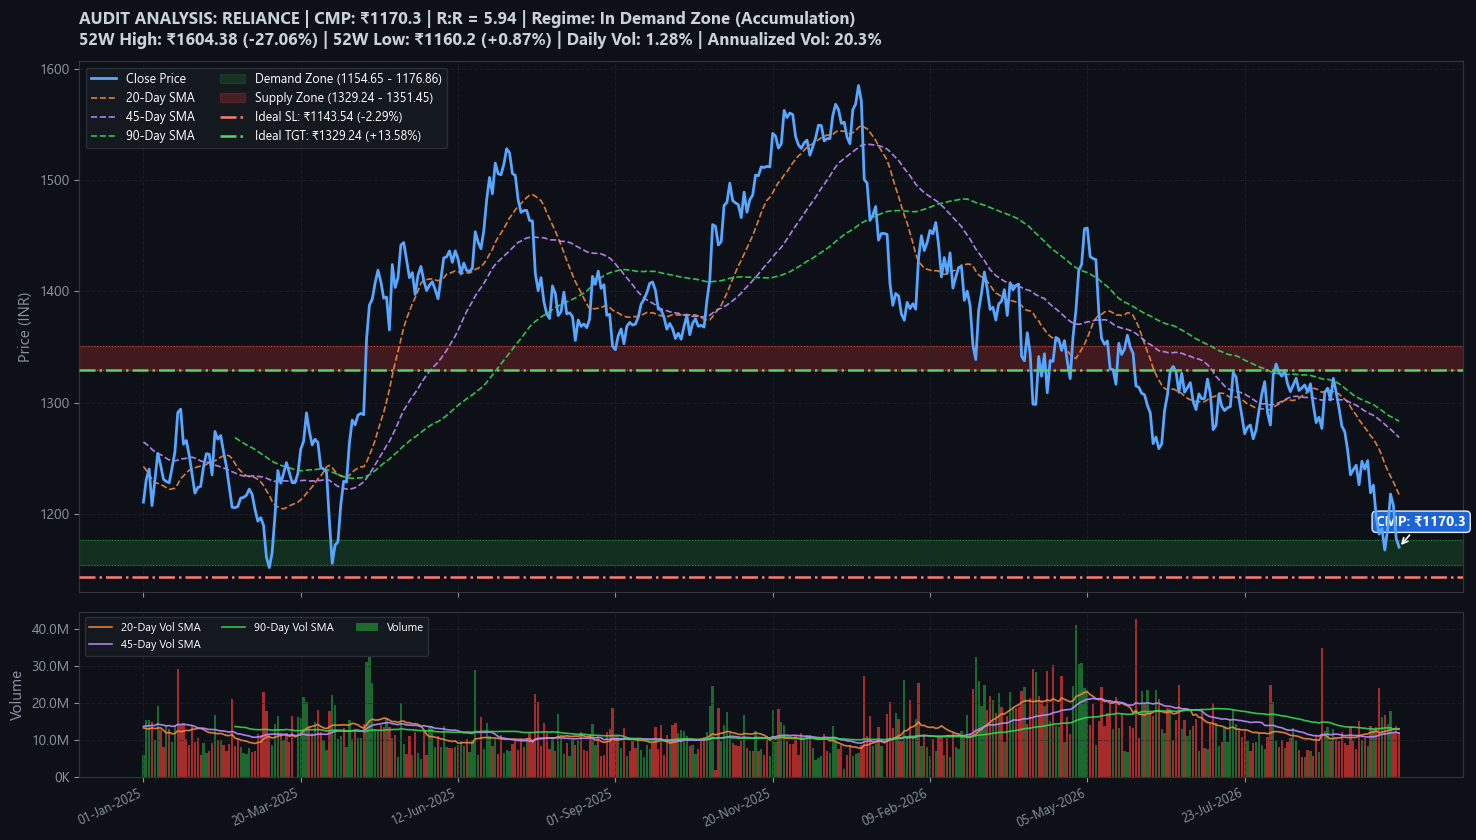

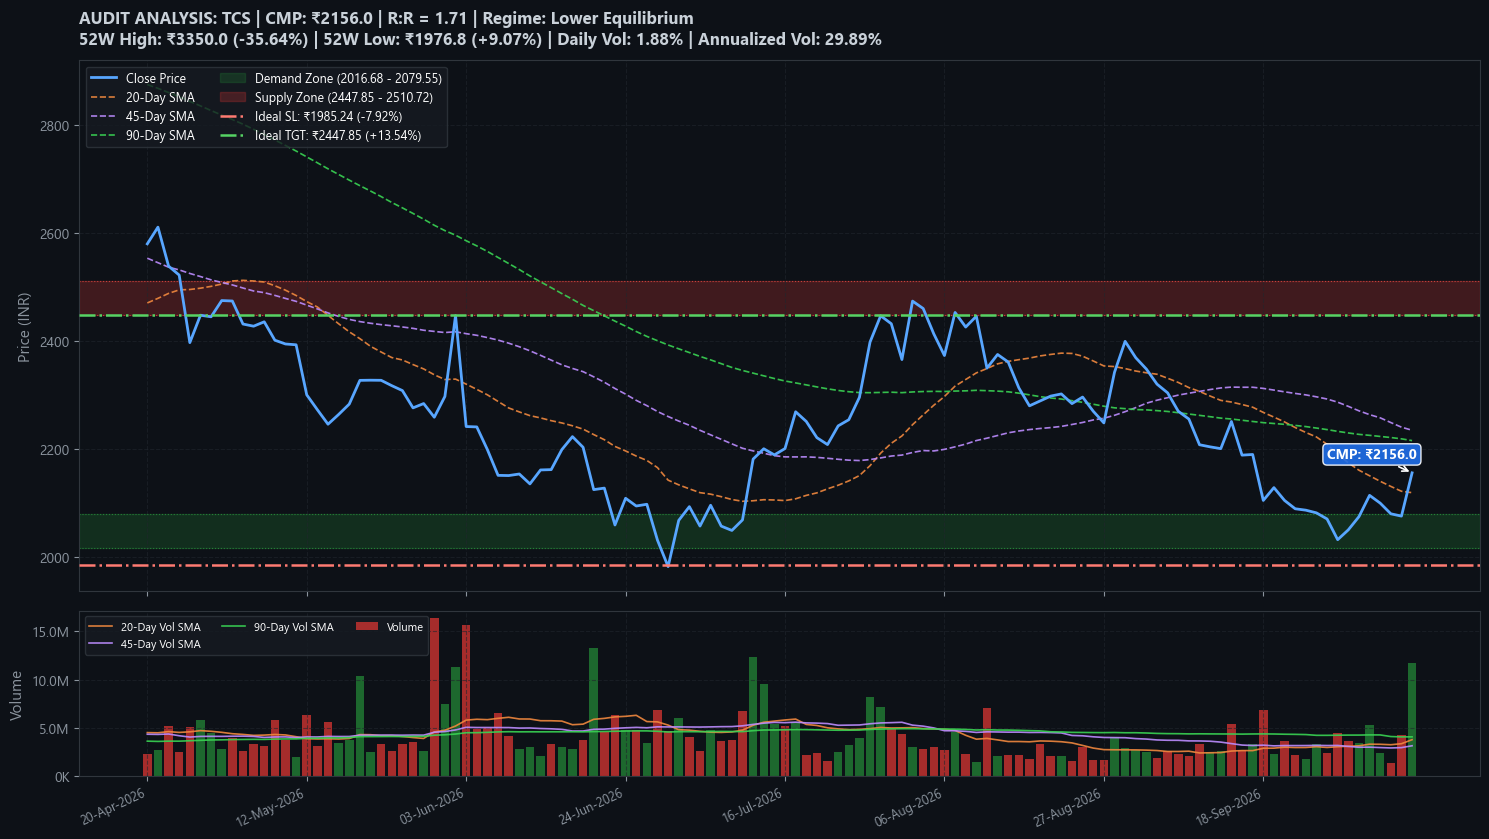

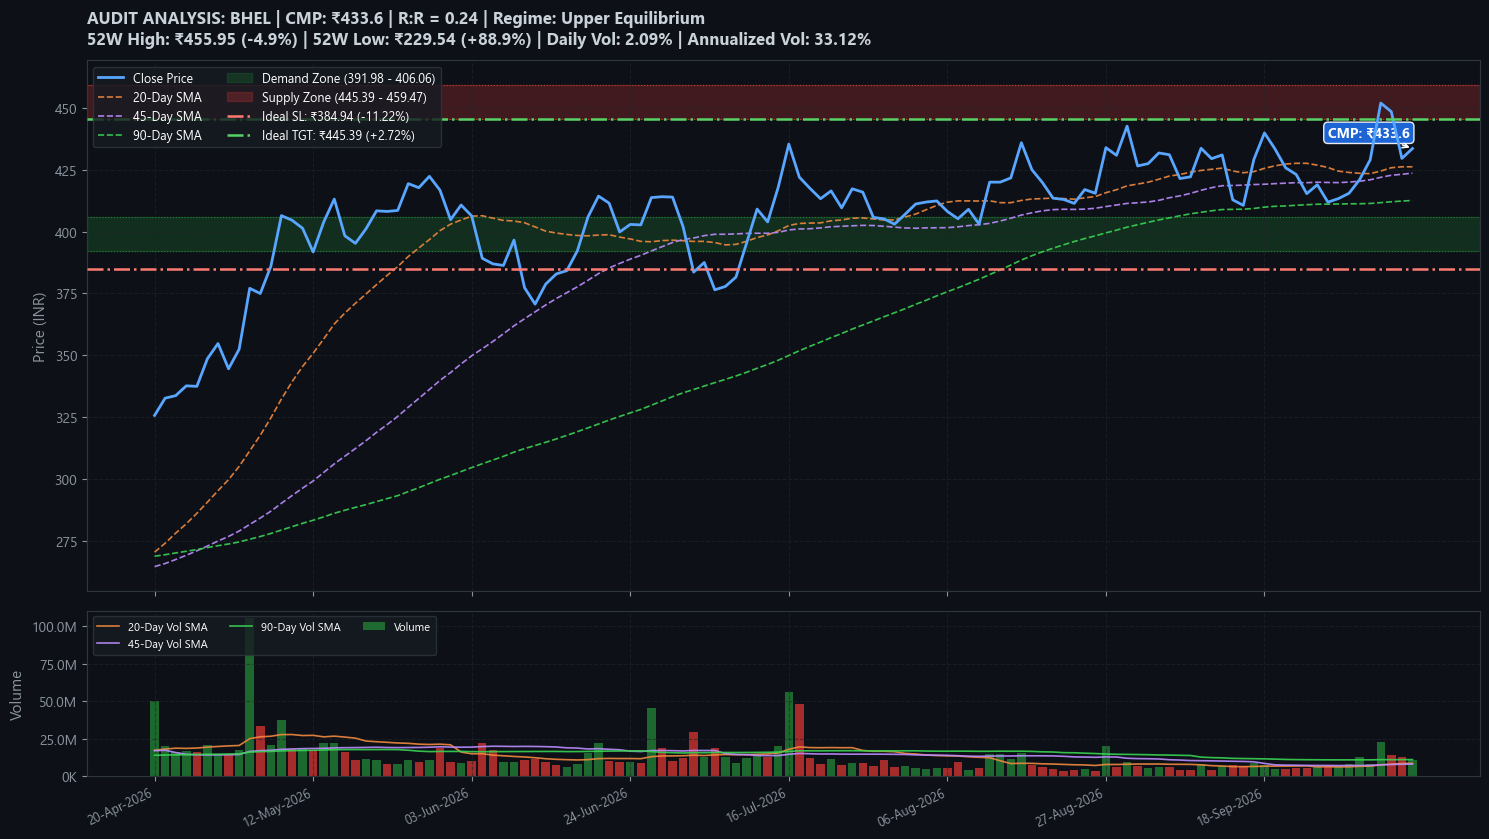

Auditing Top R:R Screener Pick: LUPIN


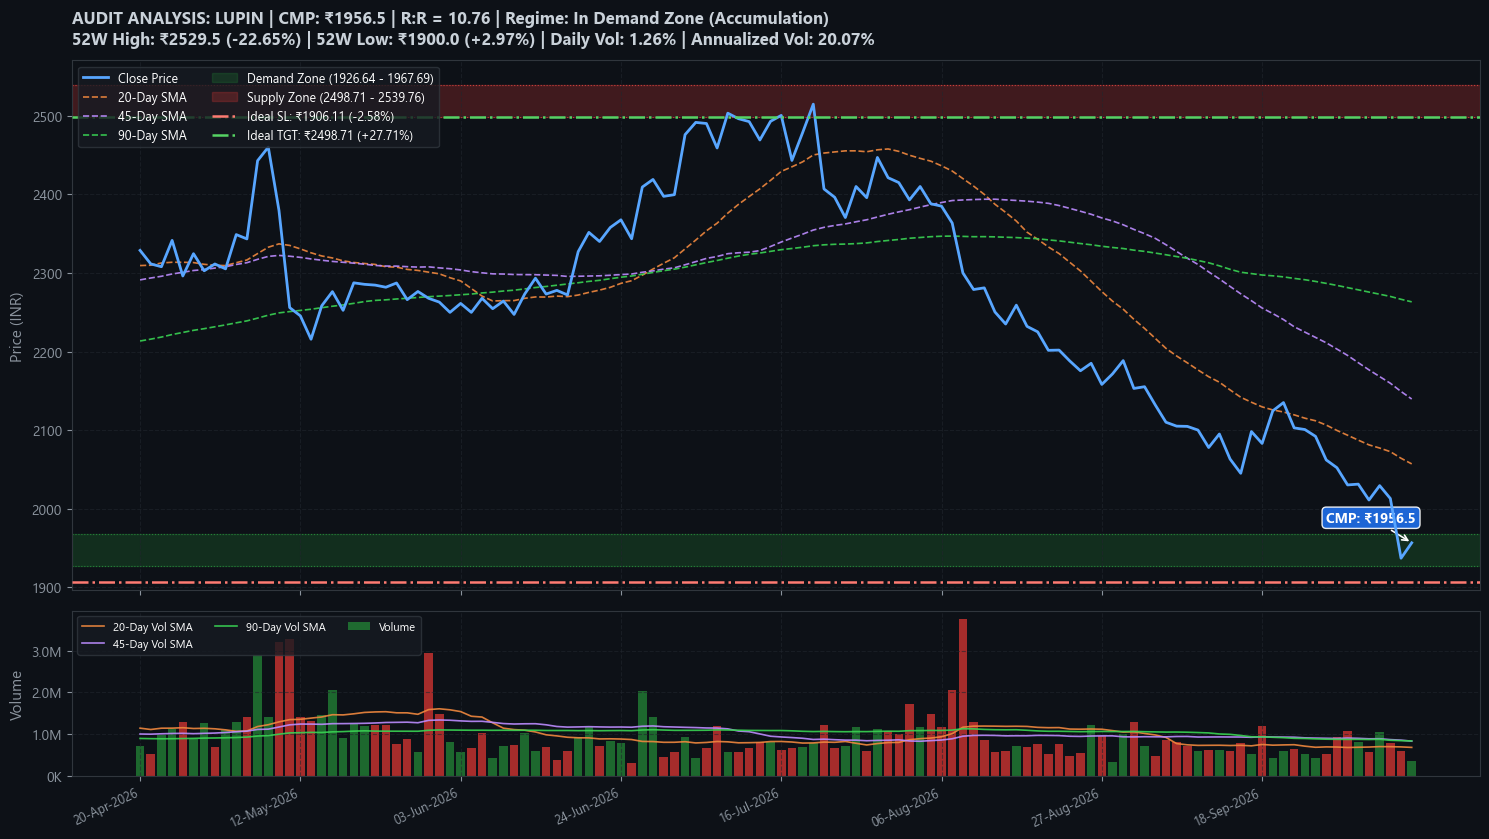

In [8]:
# Run Audit on 4 Representative Stocks:
# 1. RELIANCE (Heavyweight Index Bellwether)
audit_stock_zones('RELIANCE', lookback=440)

# 2. TCS (IT Sector Anchor)
audit_stock_zones('TCS', lookback=120)

# 3. BHEL (High Momentum PSU / Cyclical)
audit_stock_zones('BHEL', lookback=120)

# 4. Top ranked R:R Opportunity from Screener
top_pick = demand_opportunities.iloc[0]['Symbol']
print(f"Auditing Top R:R Screener Pick: {top_pick}")
audit_stock_zones(top_pick, lookback=120)


In [9]:
def filter_zone_flow_states(universe_dfs, min_vol_ratio=1.2, rebound_min_ret=0.5):
    """
    Classifies all stocks into 4 structural market states:
    1. Demand Breakdown (High Volume)
    2. Supply Breakout (High Volume)
    3. Demand Zone Rebound (Bullish Defense)
    4. Supply Zone Rebound / Rejection (Bearish Pullback)
    """
    records = []
    
    for symbol, df in universe_dfs.items():
        if len(df) < 70:
            continue
            
        df = df.copy()
        df['atr'] = compute_atr(df, period=ATR_PERIOD)
        df['vol_sma20'] = df['volume'].rolling(20).mean()
        
        curr = df.iloc[-1]
        prev = df.iloc[-2]
        # Trailing 60-session base prior to current session
        hist = df.iloc[-63:-3] if len(df) >= 65 else df.iloc[:-3]
        
        atr = curr['atr'] if not np.isnan(curr['atr']) else curr['close'] * 0.02
        vol_ratio = curr['volume'] / curr['vol_sma20'] if curr['vol_sma20'] > 0 else 1.0
        prev_vol_ratio = prev['volume'] / df['vol_sma20'].iloc[-2] if df['vol_sma20'].iloc[-2] > 0 else 1.0
        day_ret = ((curr['close'] - prev['close']) / prev['close']) * 100.0
        
        # Intermediate swing pivots over lookback
        pivot_lows = []
        pivot_highs = []
        for i in range(2, len(hist) - 2):
            if hist['low'].iloc[i] == hist['low'].iloc[i-2:i+3].min():
                pivot_lows.append(hist['low'].iloc[i])
            if hist['high'].iloc[i] == hist['high'].iloc[i-2:i+3].max():
                pivot_highs.append(hist['high'].iloc[i])
                
        # Demand Zone boundaries
        recent_p_lows = [p for p in pivot_lows if p <= prev['close'] + 0.5 * atr]
        support_lvl = max(recent_p_lows) if recent_p_lows else hist['low'].min()
        d_floor = round(support_lvl - 0.25 * atr, 2)
        d_ceil = round(support_lvl + 0.75 * atr, 2)
        
        # Supply Zone boundaries
        recent_p_highs = [p for p in pivot_highs if p >= prev['close'] - 0.5 * atr]
        resist_lvl = min(recent_p_highs) if recent_p_highs else hist['high'].max()
        s_floor = round(resist_lvl - 0.75 * atr, 2)
        s_ceil = round(resist_lvl + 0.25 * atr, 2)
        
        # 1. Broken BELOW Demand Zone with High Volume
        is_breakdown_demand_hv = (
            (curr['close'] < d_floor and vol_ratio >= min_vol_ratio) or
            (prev['close'] < d_floor and prev_vol_ratio >= min_vol_ratio)
        )
        
        # 2. Broken ABOVE Supply Zone with High Volume
        is_breakout_supply_hv = (
            (curr['close'] > s_ceil and vol_ratio >= min_vol_ratio) or
            (prev['close'] > s_ceil and prev_vol_ratio >= min_vol_ratio)
        )
        
        # 3. Rebounding from Demand Zone (Bullish Defense)
        is_demand_rebound = (
            (curr['low'] <= d_ceil) and 
            (curr['close'] >= d_floor) and 
            (curr['close'] > curr['open']) and 
            (day_ret >= rebound_min_ret)
        )
        
        # 4. Rebounding / Rejecting Down from Supply Zone (Bearish Exhaustion)
        is_supply_rejection = (
            (curr['high'] >= s_floor) and 
            (curr['close'] <= s_ceil) and 
            (curr['close'] < curr['open']) and 
            (day_ret <= -rebound_min_ret)
        )
        
        ideal_sl = round(d_floor - 0.50 * atr, 2)
        ideal_tgt = round(s_floor, 2) if curr['close'] < s_floor else round(s_ceil + 2.0 * atr, 2)
        risk_pts = curr['close'] - ideal_sl
        reward_pts = ideal_tgt - curr['close']
        rr = round(reward_pts / risk_pts, 2) if risk_pts > 0 else 0.0

        records.append({
            'Symbol': symbol,
            'Close': round(curr['close'], 2),
            'Day_Return_%': round(day_ret, 2),
            'Volume': int(curr['volume']),
            'Vol_Ratio_20x': round(vol_ratio, 2),
            'Prev_Vol_Ratio_20x': round(prev_vol_ratio, 2),
            'Demand_Zone': f"{d_floor} - {d_ceil}",
            'Supply_Zone': f"{s_floor} - {s_ceil}",
            'Ideal_SL': ideal_sl,
            'Ideal_Target': ideal_tgt,
            'R:R_Ratio': rr,
            'Demand_Breakdown_HV': is_breakdown_demand_hv,
            'Supply_Breakout_HV': is_breakout_supply_hv,
            'Demand_Rebound': is_demand_rebound,
            'Supply_Rejection': is_supply_rejection
        })
        
    return pd.DataFrame(records)

# Run scan
zone_flow_df = filter_zone_flow_states(universe_dfs, min_vol_ratio=1.2, rebound_min_ret=0.5)

# -------------------------------------------------------------------------
# DISPLAY 4 SHORTLIST TABLES
# -------------------------------------------------------------------------
# 1. Demand Breakdowns with High Vol
print("=== FILTER 1: BROKEN BELOW DEMAND ZONE WITH HIGH VOL ===")
display(zone_flow_df[zone_flow_df['Demand_Breakdown_HV']].sort_values(by='Vol_Ratio_20x', ascending=False))

# 2. Supply Breakouts with High Vol
print("\n=== FILTER 2: BROKEN ABOVE SUPPLY ZONE WITH HIGH VOL ===")
display(zone_flow_df[zone_flow_df['Supply_Breakout_HV']].sort_values(by='Vol_Ratio_20x', ascending=False))

# 3. Rebound from Demand Zone
print("\n=== FILTER 3: REBOUNDING FROM DEMAND ZONE ===")
display(zone_flow_df[zone_flow_df['Demand_Rebound']].sort_values(by=['Day_Return_%', 'Vol_Ratio_20x'], ascending=[False, False]).head(15))

# 4. Rebounding / Rejecting from Supply Zone
print("\n=== FILTER 4: REBOUNDING / REJECTING FROM SUPPLY ZONE ===")
display(zone_flow_df[zone_flow_df['Supply_Rejection']].sort_values(by='Day_Return_%', ascending=True))

=== FILTER 1: BROKEN BELOW DEMAND ZONE WITH HIGH VOL ===


,Symbol,Close,Day_Return_%,Volume,Vol_Ratio_20x,Prev_Vol_Ratio_20x,Demand_Zone,Supply_Zone,Ideal_SL,Ideal_Target,R:R_Ratio,Demand_Breakdown_HV,Supply_Breakout_HV,Demand_Rebound,Supply_Rejection
3,APOLLOHOSP,8027.50,4.72,1449612,2.35,1.65,7752.76 - 7965.72,8729.28 - 8942.24,7646.28,8729.28,1.84,True,False,True,False
56,BEL,368.15,0.23,17198740,1.64,1.31,375.02 - 382.93,394.72 - 402.63,371.07,394.72,0.00,True,False,False,False
27,ITC,266.00,4.31,31030528,1.61,2.95,256.08 - 262.56,263.64 - 270.12,252.84,283.07,1.30,True,False,True,False
103,SIEMENS,3595.00,-1.21,353854,1.42,0.96,3654.9 - 3764.91,3626.79 - 3736.8,3599.89,3626.79,0.00,True,False,False,True
49,AMBUJACEM,351.50,3.08,2615221,1.40,1.40,353.89 - 363.52,388.78 - 398.41,349.08,388.78,15.40,True,False,False,False
81,JINDALSTEL,1016.70,0.66,1388342,1.32,2.13,1012.47 - 1046.58,1024.92 - 1059.03,995.42,1024.92,0.39,True,False,True,False
82,LICHSGFIN,551.65,2.73,5310443,1.28,3.62,538.96 - 557.13,529.77 - 547.94,529.87,584.29,1.50,True,True,True,False
106,TATACOMM,1656.70,-1.23,307617,1.25,2.14,1672.54 - 1722.37,1660.53 - 1710.36,1647.63,1660.53,0.42,True,False,False,True
36,POWERGRID,249.15,1.84,11518140,1.15,1.44,251.0 - 256.4,264.9 - 270.3,248.30,264.90,18.53,True,False,False,False
107,TATAPOWER,342.15,1.94,4378116,1.11,1.57,344.38 - 352.47,364.68 - 372.77,340.34,364.68,12.45,True,False,False,False



=== FILTER 2: BROKEN ABOVE SUPPLY ZONE WITH HIGH VOL ===


,Symbol,Close,Day_Return_%,Volume,Vol_Ratio_20x,Prev_Vol_Ratio_20x,Demand_Zone,Supply_Zone,Ideal_SL,Ideal_Target,R:R_Ratio,Demand_Breakdown_HV,Supply_Breakout_HV,Demand_Rebound,Supply_Rejection
2,ADANIPORTS,1761.00,3.10,9906351,4.07,1.51,1703.91 - 1752.28,1667.12 - 1715.49,1679.73,1812.23,0.63,False,True,True,False
101,SAIL,171.55,3.19,42339535,2.62,0.93,166.77 - 173.53,161.12 - 167.88,163.39,181.39,1.21,False,True,True,False
94,PERSISTENT,5770.00,5.52,773886,1.76,0.77,5459.27 - 5626.19,5468.81 - 5635.73,5375.81,5969.56,0.51,False,True,True,False
29,KOTAKBANK,441.00,1.38,31536992,1.44,1.06,416.49 - 426.34,428.21 - 438.06,411.56,457.76,0.57,False,True,False,False
82,LICHSGFIN,551.65,2.73,5310443,1.28,3.62,538.96 - 557.13,529.77 - 547.94,529.87,584.29,1.50,True,True,True,False
47,TRENT,2918.20,1.46,753581,0.68,1.22,2873.49 - 2948.32,2791.78 - 2866.61,2836.08,3016.26,1.19,False,True,True,False



=== FILTER 3: REBOUNDING FROM DEMAND ZONE ===


,Symbol,Close,Day_Return_%,Volume,Vol_Ratio_20x,Prev_Vol_Ratio_20x,Demand_Zone,Supply_Zone,Ideal_SL,Ideal_Target,R:R_Ratio,Demand_Breakdown_HV,Supply_Breakout_HV,Demand_Rebound,Supply_Rejection
94,PERSISTENT,5770.00,5.52,773886,1.76,0.77,5459.27 - 5626.19,5468.81 - 5635.73,5375.81,5969.56,0.51,False,True,True,False
3,APOLLOHOSP,8027.50,4.72,1449612,2.35,1.65,7752.76 - 7965.72,8729.28 - 8942.24,7646.28,8729.28,1.84,True,False,True,False
70,GLENMARK,2293.00,4.60,414339,0.68,1.34,2204.83 - 2275.5,2195.8 - 2266.47,2169.49,2407.81,0.93,True,False,True,False
27,ITC,266.00,4.31,31030528,1.61,2.95,256.08 - 262.56,263.64 - 270.12,252.84,283.07,1.30,True,False,True,False
16,EICHERMOT,7050.00,4.17,551231,1.49,1.01,6802.76 - 6951.71,7457.79 - 7606.74,6728.29,7457.79,1.27,False,False,True,False
42,TCS,2156.00,3.85,11692314,3.09,1.27,2059.58 - 2122.45,2236.25 - 2299.12,2028.14,2236.25,0.63,False,False,True,False
101,SAIL,171.55,3.19,42339535,2.62,0.93,166.77 - 173.53,161.12 - 167.88,163.39,181.39,1.21,False,True,True,False
2,ADANIPORTS,1761.00,3.10,9906351,4.07,1.51,1703.91 - 1752.28,1667.12 - 1715.49,1679.73,1812.23,0.63,False,True,True,False
114,NIFTY IT,28574.90,3.02,0,1.00,1.00,27455.6 - 28084.61,29011.39 - 29640.4,27141.09,29011.39,0.30,False,False,True,False
76,IGL,146.15,2.90,2395557,1.33,1.07,138.2 - 142.21,143.89 - 147.9,136.19,155.93,0.98,False,False,True,False



=== FILTER 4: REBOUNDING / REJECTING FROM SUPPLY ZONE ===


,Symbol,Close,Day_Return_%,Volume,Vol_Ratio_20x,Prev_Vol_Ratio_20x,Demand_Zone,Supply_Zone,Ideal_SL,Ideal_Target,R:R_Ratio,Demand_Breakdown_HV,Supply_Breakout_HV,Demand_Rebound,Supply_Rejection
52,BALRAMCHIN,678.15,-1.64,738592,0.56,1.04,649.98 - 679.25,683.4 - 712.67,635.35,683.40,0.12,False,False,False,True
106,TATACOMM,1656.70,-1.23,307617,1.25,2.14,1672.54 - 1722.37,1660.53 - 1710.36,1647.63,1660.53,0.42,True,False,False,True
103,SIEMENS,3595.00,-1.21,353854,1.42,0.96,3654.9 - 3764.91,3626.79 - 3736.8,3599.89,3626.79,0.00,True,False,False,True
71,GNFC,592.70,-1.09,335320,0.27,0.31,570.59 - 592.24,580.71 - 602.36,559.77,645.66,1.61,False,False,False,True
91,NAVINFLUOR,8352.50,-0.77,43911,0.40,0.73,8450.67 - 8670.0,8260.5 - 8479.83,8341.00,8918.50,49.22,False,False,False,True


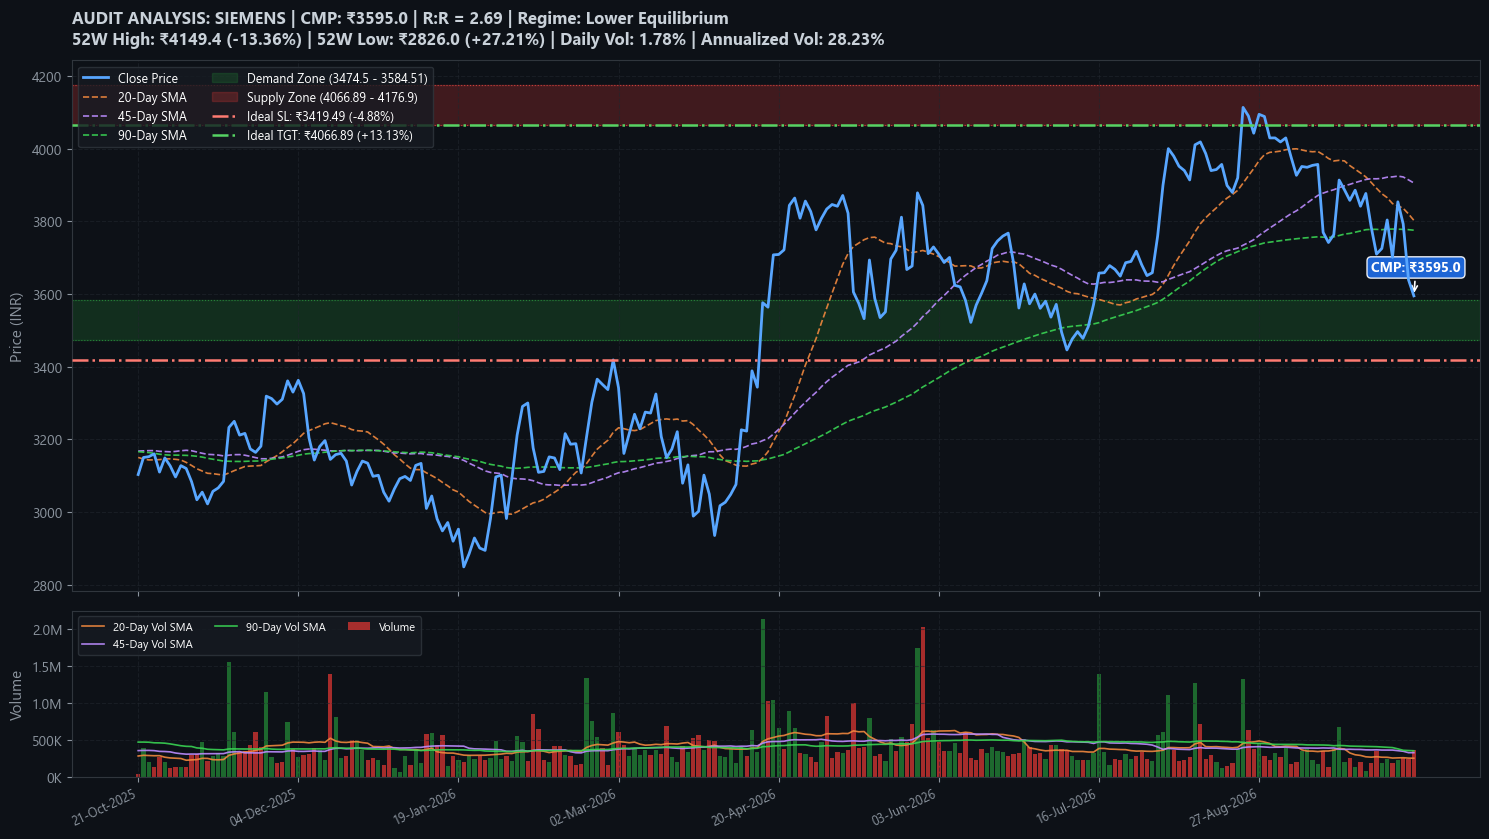

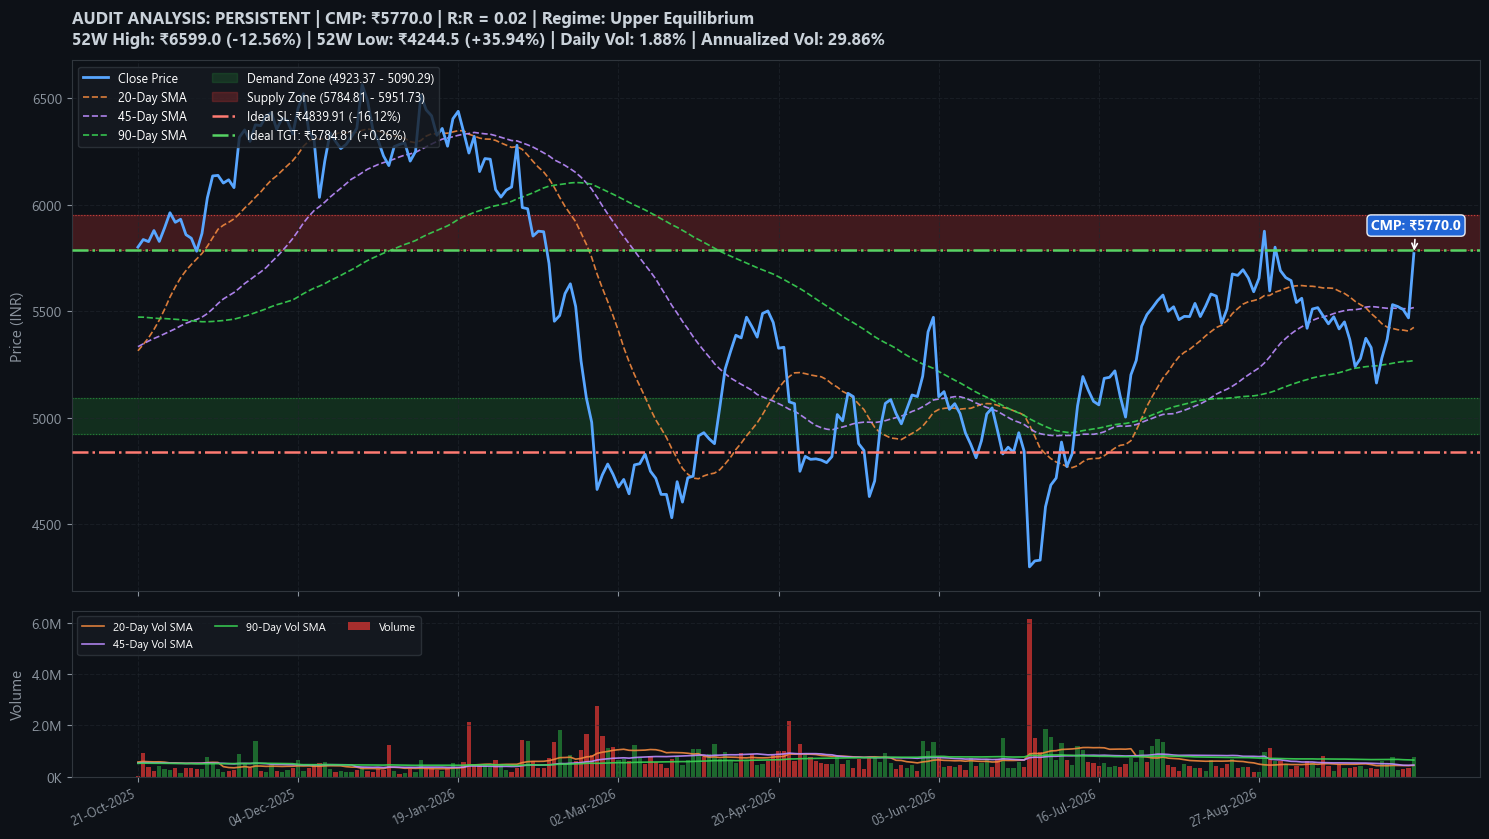

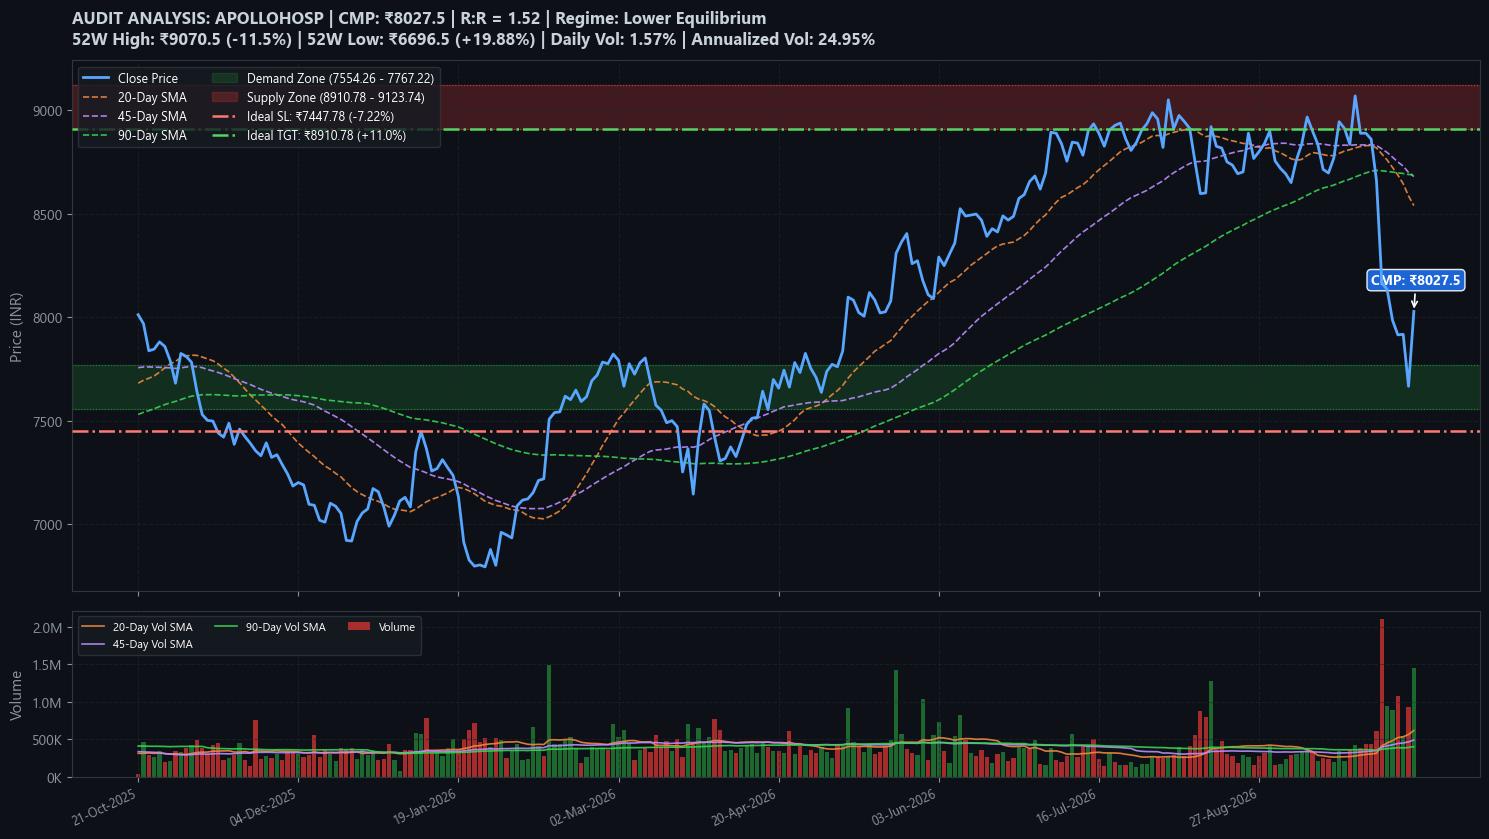

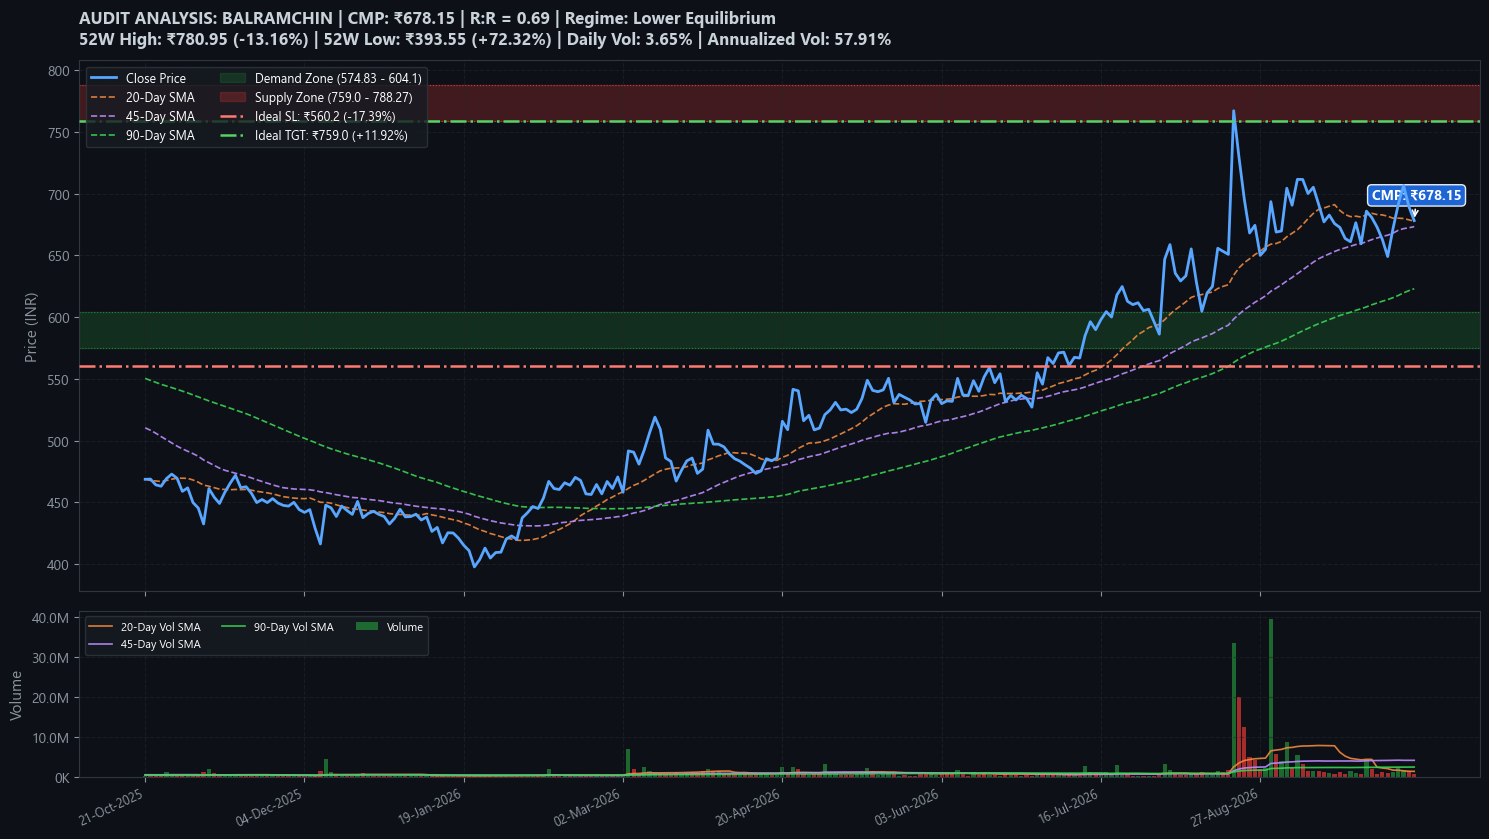

In [10]:

# Run visual audits:
audit_stock_zones('SIEMENS',240)     # Demand Breakdown
audit_stock_zones('PERSISTENT',240)  # Supply Breakout
audit_stock_zones('APOLLOHOSP',240)  # Demand Rebound
audit_stock_zones('BALRAMCHIN',240)  # Supply Rejection

---
## 🔬 Support & Resistance (S/R) Level Quality & Confirmation Engine

A critical decision point for traders is: **Is this price level truly a verified Support or Resistance, or is it just an arbitrary price point?**

To eliminate false signals and validate genuine institutional supply/demand boundaries, we evaluate every level across **5 Quantitative Pillars**:

1. **Reaction / Touch Frequency ($N_{\text{touch}}$)**:
   - Measures how many distinct trading sessions tested within the level's volatility tolerance band ($[L - 0.5\times\text{ATR}, L + 0.5\times\text{ATR}]$).
   - $\ge 3$ touches confirm an established structural memory where market participants actively place limit orders.

2. **Rejection Wick Ratio (Institutional Absorption)**:
   - Evaluates candlestick geometry at the level.
   - For Support: Measures instances where the lower wick represents $\ge 40\%$ of the candle's total daily range (aggressive buyer absorption preventing downside closes).
   - For Resistance: Measures instances where the upper wick represents $\ge 40\%$ of the total range (aggressive seller distribution capping rallies).

3. **Polarity Principle / Role Reversal**:
   - Wyckoff & classical technical theory proves that the strongest support levels are *prior resistance levels that broke out and were re-tested from above* (and vice versa for broken support turning into resistance).
   - Confirms institutional structural flips.

4. **Volume Concentration / Institutional Footprint**:
   - Measures the average trading volume during test sessions relative to the 20-Day Volume SMA.
   - Test sessions with Volume Ratio $\ge 1.2\times$ confirm institutional order execution rather than low-liquidity retail drift.

5. **Composite S/R Strength Score (0 to 100) & Quality Grade**:
   - **Score = $\min(40, N_{\text{touch}} \times 10) + \min(25, N_{\text{rejection}} \times 8) + (20 \text{ if Role Flip}) + \text{Volume Points}$**
   - **Grades**:
     - **Grade A+ (Score $\ge 75$)**: *Major Institutional S/R* — High reliability, heavy multi-touch absorption, verified flip.
     - **Grade A (Score $55 - 74$)**: *Established S/R* — Proven structural pivot with multiple rejections.
     - **Grade B (Score $35 - 54$)**: *Emerging / Secondary S/R* — Valid local pivot, requires volume confirmation.
     - **Grade C (Score $< 35$)**: *Unconfirmed / Fragile* — Single-touch level, high risk of false breakout/down.


In [11]:
def validate_support_resistance_quality(df, lookback=120):
    """
    Quantitatively scores the authenticity and strength of Support and Resistance levels
    for a given stock DataFrame over a specified lookback window.
    """
    df = df.copy()
    tr = compute_atr(df, period=ATR_PERIOD)
    df['atr'] = tr
    df['vol_sma20'] = df['volume'].rolling(20).mean()
    
    sub = df.iloc[-lookback:].copy().reset_index(drop=True)
    curr = sub.iloc[-1]
    cmp = curr['close']
    atr = curr['atr'] if not np.isnan(curr['atr']) else cmp * 0.02
    tol = 0.5 * atr  # Volatility tolerance band around level
    
    # Identify swing pivots (5-bar window)
    pivot_lows = []
    pivot_highs = []
    for i in range(2, len(sub)-2):
        if sub['low'].iloc[i] == sub['low'].iloc[i-2:i+3].min():
            pivot_lows.append((i, sub['date'].iloc[i], sub['low'].iloc[i], sub['volume'].iloc[i]))
        if sub['high'].iloc[i] == sub['high'].iloc[i-2:i+3].max():
            pivot_highs.append((i, sub['date'].iloc[i], sub['high'].iloc[i], sub['volume'].iloc[i]))
            
    def score_single_level(level, is_support=True):
        touches = 0
        rejections = 0
        volume_at_level = []
        first_touch_idx = len(sub)
        
        for i in range(len(sub) - 1):
            bar = sub.iloc[i]
            # Price interacted with [level - tol, level + tol]
            if (bar['low'] <= level + tol) and (bar['high'] >= level - tol):
                touches += 1
                first_touch_idx = min(first_touch_idx, i)
                vol_ratio = bar['volume'] / sub['vol_sma20'].iloc[i] if sub['vol_sma20'].iloc[i] > 0 else 1.0
                volume_at_level.append(vol_ratio)
                
                # Candlestick Rejection Geometry
                c_range = bar['high'] - bar['low']
                body_min = min(bar['open'], bar['close'])
                body_max = max(bar['open'], bar['close'])
                
                if c_range > 0:
                    if is_support:
                        lower_wick = body_min - bar['low']
                        if (lower_wick / c_range) >= 0.40:
                            rejections += 1
                    else:
                        upper_wick = bar['high'] - body_max
                        if (upper_wick / c_range) >= 0.40:
                            rejections += 1

        # Check Polarity / Role Reversals
        if is_support:
            flips = [h for idx, dt, h, vol in pivot_highs if abs(h - level) <= tol]
        else:
            flips = [l for idx, dt, l, vol in pivot_lows if abs(l - level) <= tol]
        role_flips = len(flips)
        
        avg_vol = float(np.mean(volume_at_level)) if volume_at_level else 1.0
        age_bars = len(sub) - first_touch_idx
        
        # Multi-factor score (0-100)
        touch_pts = min(40, touches * 10)
        rejection_pts = min(25, rejections * 8)
        flip_pts = 20 if role_flips > 0 else 0
        vol_pts = 15 if avg_vol >= 1.2 else (10 if avg_vol >= 1.0 else 5)
        
        total_score = touch_pts + rejection_pts + flip_pts + vol_pts
        total_score = min(100, max(0, total_score))
        
        if total_score >= 75:
            grade = 'A+ (Major Institutional)'
        elif total_score >= 55:
            grade = 'A (Established)'
        elif total_score >= 35:
            grade = 'B (Emerging/Minor)'
        else:
            grade = 'C (Fragile/Unconfirmed)'
            
        return {
            'Level': round(level, 2),
            'Touches': touches,
            'Rejections': rejections,
            'Role_Flips': role_flips,
            'Avg_Vol_Ratio': round(avg_vol, 2),
            'Age_Days': age_bars,
            'Score': total_score,
            'Grade': grade
        }

    # Evaluate Nearest Support below CMP
    p_low_vals = [p[2] for p in pivot_lows if p[2] <= cmp + 0.2 * atr]
    nearest_sup_lvl = max(p_low_vals) if p_low_vals else sub['low'].min()
    
    # Evaluate Nearest Resistance above CMP
    p_high_vals = [p[2] for p in pivot_highs if p[2] >= cmp - 0.2 * atr]
    nearest_res_lvl = min(p_high_vals) if p_high_vals else sub['high'].max()
    
    sup_metrics = score_single_level(nearest_sup_lvl, is_support=True)
    res_metrics = score_single_level(nearest_res_lvl, is_support=False)
    
    return sup_metrics, res_metrics

print("Support/Resistance Quality Validation Engine compiled successfully.")


Support/Resistance Quality Validation Engine compiled successfully.


In [12]:
# Generate S/R Quality Audit across Universe
sr_records = []
for symbol, df_sym in universe_dfs.items():
    if len(df_sym) < 70:
        continue
    sup_m, res_m = validate_support_resistance_quality(df_sym, lookback=120)
    curr_c = df_sym['close'].iloc[-1]
    
    # Distance to support & resistance
    dist_sup_pct = round(((curr_c - sup_m['Level']) / curr_c) * 100.0, 2)
    dist_res_pct = round(((res_m['Level'] - curr_c) / curr_c) * 100.0, 2)
    
    sr_records.append({
        'Symbol': symbol,
        'CMP': round(curr_c, 2),
        'Support_Lvl': sup_m['Level'],
        'Dist_to_Sup_%': dist_sup_pct,
        'Sup_Touches': sup_m['Touches'],
        'Sup_Rejections': sup_m['Rejections'],
        'Sup_Flips': sup_m['Role_Flips'],
        'Sup_Score': sup_m['Score'],
        'Sup_Grade': sup_m['Grade'],
        'Resist_Lvl': res_m['Level'],
        'Dist_to_Res_%': dist_res_pct,
        'Res_Touches': res_m['Touches'],
        'Res_Rejections': res_m['Rejections'],
        'Res_Flips': res_m['Role_Flips'],
        'Res_Score': res_m['Score'],
        'Res_Grade': res_m['Grade']
    })

sr_quality_df = pd.DataFrame(sr_records).sort_values('Symbol').reset_index(drop=True)

print(f"Validated S/R quality metrics for {len(sr_quality_df)} stocks.")

# Display top high-conviction support levels near CMP (Within 3% of Major Institutional Support)
high_conviction_supports = sr_quality_df[
    (sr_quality_df['Dist_to_Sup_%'].between(0.0, 3.5)) & 
    (sr_quality_df['Sup_Score'] >= 75)
].sort_values(by='Sup_Score', ascending=False)

print(f"\n=== HIGH-CONVICTION STOCKS AT MAJOR INSTITUTIONAL SUPPORT (GRADE A+) ({len(high_conviction_supports)} FOUND) ===")
display_cols_sup = ['Symbol', 'CMP', 'Support_Lvl', 'Dist_to_Sup_%', 'Sup_Touches', 'Sup_Rejections', 'Sup_Flips', 'Sup_Score', 'Sup_Grade']
display(high_conviction_supports[display_cols_sup].head(15))


Validated S/R quality metrics for 115 stocks.

=== HIGH-CONVICTION STOCKS AT MAJOR INSTITUTIONAL SUPPORT (GRADE A+) (37 FOUND) ===


,Symbol,CMP,Support_Lvl,Dist_to_Sup_%,Sup_Touches,Sup_Rejections,Sup_Flips,Sup_Score,Sup_Grade
106,TECHM,1514.10,1510.50,0.24,23,4,1,100,A+ (Major Institutional)
12,BALRAMCHIN,678.15,657.30,3.07,30,6,2,100,A+ (Major Institutional)
3,APOLLOHOSP,8027.50,7981.00,0.58,19,3,1,99,A+ (Major Institutional)
39,GNFC,592.70,576.00,2.82,27,3,3,99,A+ (Major Institutional)
105,TCS,2156.00,2110.00,2.13,30,8,2,95,A+ (Major Institutional)
85,PETRONET,291.50,289.00,0.86,46,9,4,95,A+ (Major Institutional)
78,NIFTY BANK,55256.65,54221.65,1.87,23,5,1,95,A+ (Major Institutional)
63,LICHSGFIN,551.65,543.50,1.48,82,21,1,95,A+ (Major Institutional)
7,AUBANK,982.00,974.20,0.79,25,6,1,95,A+ (Major Institutional)
46,HDFCLIFE,556.65,553.25,0.61,43,11,2,95,A+ (Major Institutional)


=== S/R QUALITY AUDIT: TCS ===


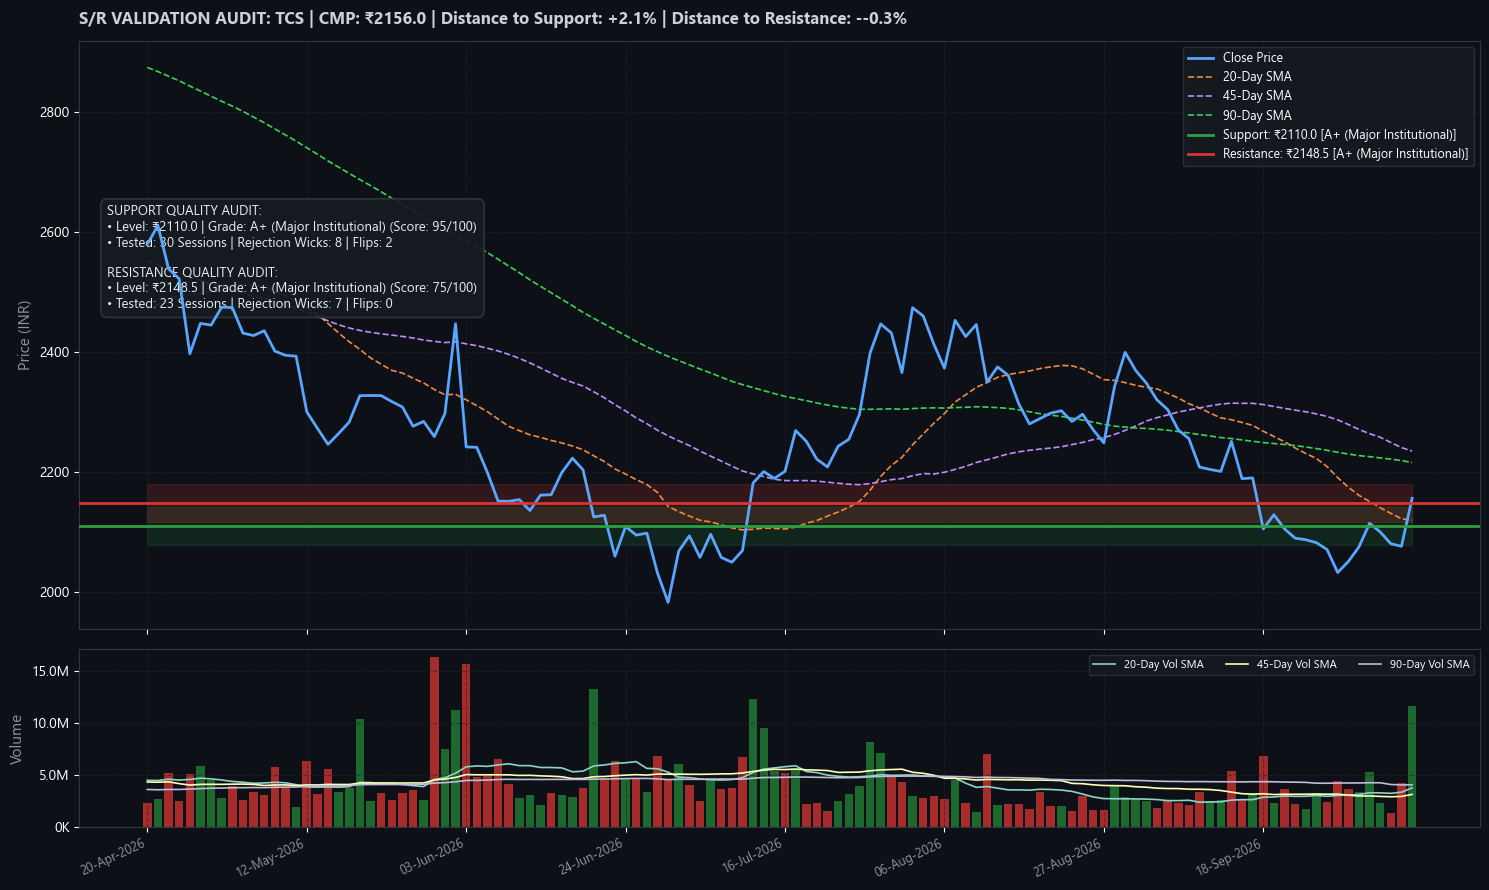

=== S/R QUALITY AUDIT: APOLLOHOSP ===


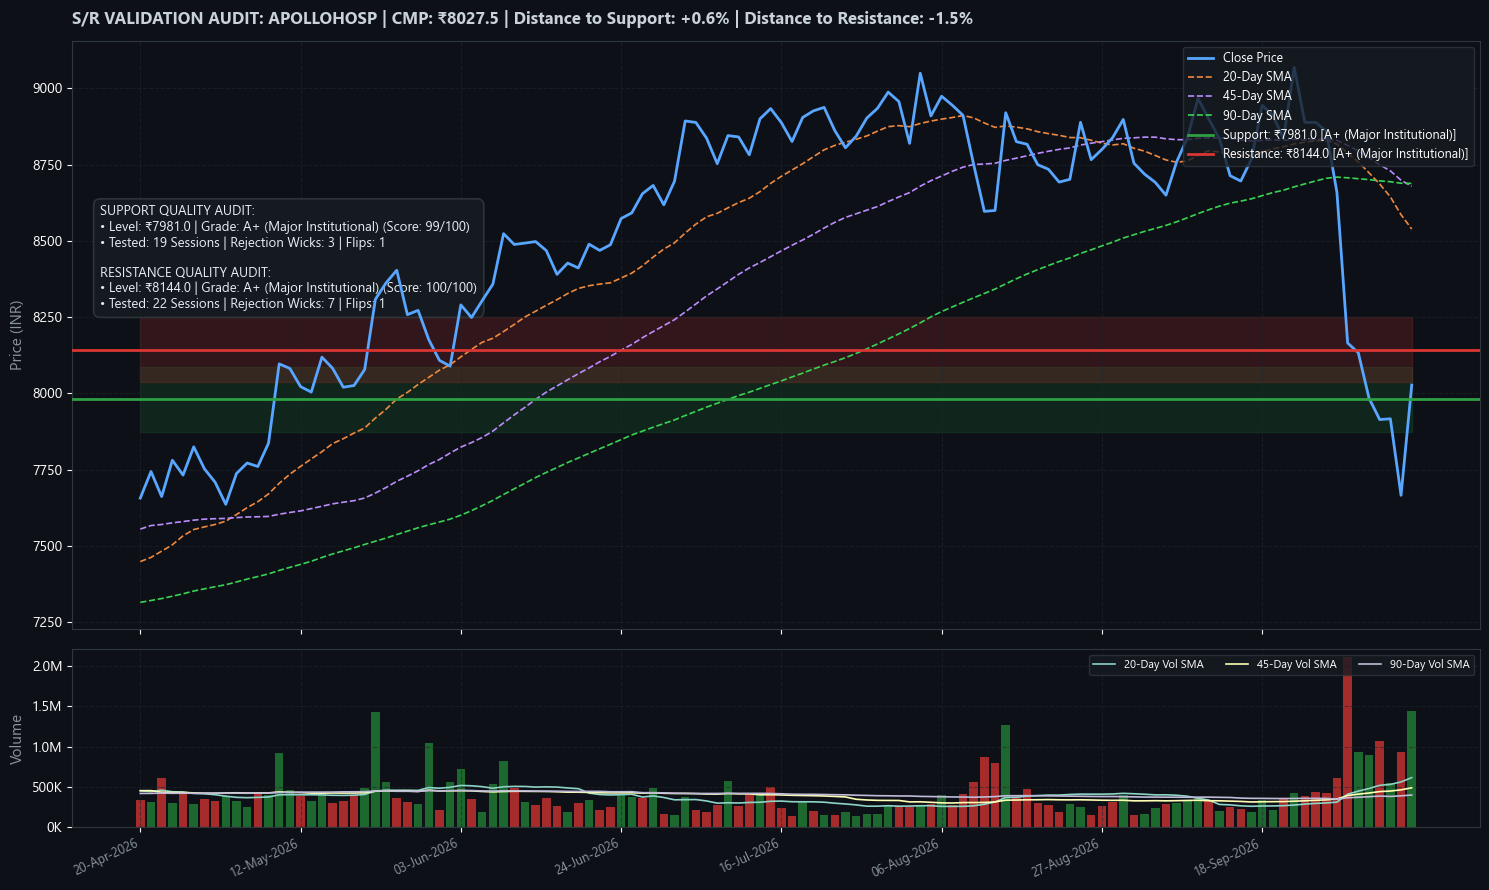

In [13]:
def audit_stock_with_sr_quality(symbol, lookback=120):
    """
    Visualizes price action, Demand/Supply bands, and adds S/R Validation Badges:
    - Renders touch markers and wick rejection annotations on the level.
    - Displays Level Quality Grade (A+, A, B, C) and Score directly on the chart.
    """
    if symbol not in universe_dfs:
        print(f"Symbol {symbol} not found.")
        return

    df = universe_dfs[symbol].copy()
    sup_m, res_m = validate_support_resistance_quality(df, lookback=lookback)
    
    for p in PRICE_SMA_CONFIG:
        df[f'sma_{p}'] = df['close'].rolling(window=p).mean()
    for v in VOLUME_SMA_CONFIG:
        df[f'vol_sma_{v}'] = df['volume'].rolling(window=v).mean()
    df['atr'] = compute_atr(df, period=ATR_PERIOD)

    plot_df = df.iloc[-lookback:].copy().reset_index(drop=True)
    curr_c = plot_df['close'].iloc[-1]
    
    fig, (ax_price, ax_vol) = plt.subplots(
        2, 1, figsize=(15, 9), gridspec_kw={'height_ratios': [3.3, 1.0]}, sharex=True
    )
    fig.patch.set_facecolor('#0d1117')
    ax_price.set_facecolor('#0d1117')
    ax_vol.set_facecolor('#0d1117')

    x = np.arange(len(plot_df))
    
    # Price and SMAs
    ax_price.plot(x, plot_df['close'], label='Close Price', color='#58a6ff', linewidth=2.0, zorder=4)
    colors_sma = {'20': '#f0883e', '45': '#bc8cff', '90': '#39d353'}
    for p in PRICE_SMA_CONFIG:
        if f'sma_{p}' in plot_df:
            ax_price.plot(x, plot_df[f'sma_{p}'], label=f'{p}-Day SMA', color=colors_sma.get(str(p), '#8b949e'), linestyle='--', linewidth=1.2)

    # Validated Support Line & Band
    s_lvl = sup_m['Level']
    ax_price.axhline(s_lvl, color='#2ea043', linestyle='-', linewidth=2.0, label=f"Support: ₹{s_lvl} [{sup_m['Grade']}]", zorder=5)
    ax_price.fill_between(x, s_lvl - (0.5 * plot_df['atr'].iloc[-1]), s_lvl + (0.5 * plot_df['atr'].iloc[-1]), color='#238636', alpha=0.18)

    # Validated Resistance Line & Band
    r_lvl = res_m['Level']
    ax_price.axhline(r_lvl, color='#da3633', linestyle='-', linewidth=2.0, label=f"Resistance: ₹{r_lvl} [{res_m['Grade']}]", zorder=5)
    ax_price.fill_between(x, r_lvl - (0.5 * plot_df['atr'].iloc[-1]), r_lvl + (0.5 * plot_df['atr'].iloc[-1]), color='#da3633', alpha=0.18)

    # Quality Badge Text Box
    badge_text = (
        f"SUPPORT QUALITY AUDIT:\n"
        f"• Level: ₹{s_lvl} | Grade: {sup_m['Grade']} (Score: {sup_m['Score']}/100)\n"
        f"• Tested: {sup_m['Touches']} Sessions | Rejection Wicks: {sup_m['Rejections']} | Flips: {sup_m['Role_Flips']}\n\n"
        f"RESISTANCE QUALITY AUDIT:\n"
        f"• Level: ₹{r_lvl} | Grade: {res_m['Grade']} (Score: {res_m['Score']}/100)\n"
        f"• Tested: {res_m['Touches']} Sessions | Rejection Wicks: {res_m['Rejections']} | Flips: {res_m['Role_Flips']}"
    )
    ax_price.text(
        0.02, 0.72, badge_text, transform=ax_price.transAxes,
        fontsize=9.5, verticalalignment='top',
        bbox=dict(boxstyle="round,pad=0.5", fc="#161b22", ec="#30363d", lw=1.2, alpha=0.92),
        color='#e6edf3'
    )

    ax_price.set_title(
        f"S/R VALIDATION AUDIT: {symbol} | CMP: ₹{curr_c} | "
        f"Distance to Support: +{round((curr_c-s_lvl)/curr_c*100, 1)}% | Distance to Resistance: -{round((r_lvl-curr_c)/curr_c*100, 1)}%",
        fontsize=12, fontweight='bold', color='#c9d1d9', pad=12, loc='left'
    )
    ax_price.set_ylabel("Price (INR)", color='#8b949e', fontsize=11)
    ax_price.legend(loc='upper right', facecolor='#161b22', edgecolor='#30363d', fontsize=9)
    ax_price.grid(True)

    # Volume Subplot
    vol_colors = ['#238636' if plot_df['close'].iloc[i] >= plot_df['open'].iloc[i] else '#da3633' for i in range(len(plot_df))]
    ax_vol.bar(x, plot_df['volume'], color=vol_colors, alpha=0.75, width=0.8)
    for v in VOLUME_SMA_CONFIG:
        if f'vol_sma_{v}' in plot_df:
            ax_vol.plot(x, plot_df[f'vol_sma_{v}'], label=f'{v}-Day Vol SMA', linewidth=1.2)
    ax_vol.set_ylabel("Volume", color='#8b949e', fontsize=11)
    ax_vol.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, p: f'{val*1e-6:.1f}M' if val >= 1e6 else f'{val*1e-3:.0f}K'))
    ax_vol.legend(loc='upper right', facecolor='#161b22', edgecolor='#30363d', fontsize=8, ncol=3)
    ax_vol.grid(True)

    # Format Dates
    tick_step = max(1, len(plot_df) // 8)
    tick_positions = x[::tick_step]
    tick_labels = [plot_df['date'].iloc[i].strftime('%d-%b-%Y') for i in tick_positions]
    ax_vol.set_xticks(tick_positions)
    ax_vol.set_xticklabels(tick_labels, rotation=25, ha='right', color='#8b949e', fontsize=9)

    plt.tight_layout()
    plt.show()

# Run Visual S/R Quality Audits on Top Setups
print("=== S/R QUALITY AUDIT: TCS ===")
audit_stock_with_sr_quality('TCS', lookback=120)

print("=== S/R QUALITY AUDIT: APOLLOHOSP ===")
audit_stock_with_sr_quality('APOLLOHOSP', lookback=120)


---
## 🌊 Institutional Market Breadth & Internal Strength Engine
### Trend Analysis: % of Stocks Above 200 SMA vs. Daily Gainer Velocity

### 1. The Quantitative Problem Statement
Individual stock screening without broad **Market Breadth** creates a dangerous blind spot:
- **Bullish Distribution Traps**: An index or heavyweight basket can grind to new highs driven by 3–5 mega-cap stocks while the underlying universe is quietly deteriorating (fewer and fewer stocks holding above their 200-day moving average). Chasing breakouts during such phases leads to severe whipsaws.
- **Leading Accumulation Waves (Breadth Thrusts)**: At market bottoms or deep corrections, daily gainers surge violently across sectors before the headline index or the lagging 200 SMA can confirm the turn.

### 2. Dual-Horizon Breadth Framework
To gauge true internal strength, we track the dynamic interplay between two complementary metrics:
1. **Structural Breadth (Lagging / Macro Regime)**:
   $$\text{Breadth}_{200} = \frac{\text{Count of Stocks with } \text{Close}_t > \text{SMA}_{200}(t)}{\text{Total Universe}} \times 100\%$$
   - The 200-day SMA is the definitive institutional benchmark distinguishing secular bull cycles from distribution regimes.
2. **Velocity / Flow Momentum (Leading / Short-Term Breadth)**:
   $$\text{Daily Advance } \% = \frac{\text{Count of Gaining Stocks } (C_t > C_{t-1})}{\text{Total Universe}} \times 100\%$$
   - Smoothed via a 10-day moving average ($\text{SMA}_{10}(\text{Advance } \%)$) to filter single-day noise and reveal sustained capital inflows.

---

### 3. Brainstormed Institutional Insights for Market Strength
In addition to the 200 SMA and Daily Gainer ratio, quantitative desks track 5 internal pillars to detect expanding market strength:
1. **Moving Average Ribbon Breadth Stack (`% > 20 EMA`, `% > 50 SMA`, `% > 200 SMA`)**:
   - **Triple Bull Expansion**: When $\% > 20 \text{ EMA} > \% > 50 \text{ SMA} > \% > 200 \text{ SMA}$, confirming momentum is accelerating from short to long timeframes.
2. **Volume-Weighted Advance Thrust (Up Volume % vs. Down Volume %)**:
   - Volume confirms conviction. Days with $\ge 80\%$ Up Volume represent institutional accumulation where large funds are aggressively deploying capital.
3. **Cumulative Advance-Decline (A/D) Line & McClellan Oscillator**:
   - The slope of the cumulative A/D line confirms index trends; positive McClellan divergence ($> 0$) spots inflection points before price breaks out.
4. **Net 52-Week Highs vs. Lows (Leadership Expansion Index)**:
   - Tracks whether leadership is broadening (more stocks touching 52-week highs) or shrinking (new 52-week lows expanding).
5. **Composite Market Strength Index (CMSI, 0 to 100)**:
   - A synthesized, weighted institutional health gauge categorized into 4 distinct trading regimes:
     - 🟢 **Strong Expansion ($\ge 70$)**: High breakout follow-through; aggressive trend trading favored.
     - 🟡 **Selective Accumulation ($50 - 70$)**: Stock-specific market; buying demand zone pullbacks favored.
     - 🟠 **Choppy Consolidation ($35 - 50$)**: Mean reversion; tight risk management; take quick profits.
     - 🔴 **Structural Distribution ($< 35$)**: High cascade breakdown risk; defensive cash / hedging favored.


In [16]:
# Build Comprehensive Daily Market Breadth & Internal Strength Time-Series
print("Building 5-year Market Breadth & Internal Strength Panels across 115 F&O Equities...")

close_dict = {}
vol_dict = {}
high_dict = {}
low_dict = {}

for sym, df_s in universe_dfs.items():
    if len(df_s) >= 70:
        s_df = df_s.set_index('date')
        close_dict[sym] = s_df['close']
        vol_dict[sym] = s_df['volume']
        high_dict[sym] = s_df['high']
        low_dict[sym] = s_df['low']

df_closes = pd.DataFrame(close_dict).sort_index()
df_vols = pd.DataFrame(vol_dict).sort_index()
df_highs = pd.DataFrame(high_dict).sort_index()
df_lows = pd.DataFrame(low_dict).sort_index()

total_active = df_closes.notna().sum(axis=1)

# 1. Multi-Horizon Moving Average Breadth
sma200_panel = df_closes.rolling(200, min_periods=100).mean()
sma50_panel = df_closes.rolling(50, min_periods=25).mean()
ema20_panel = df_closes.ewm(span=20, min_periods=10, adjust=False).mean()

pct_above_200 = ((df_closes > sma200_panel).sum(axis=1) / sma200_panel.notna().sum(axis=1)) * 100.0
pct_above_50 = ((df_closes > sma50_panel).sum(axis=1) / sma50_panel.notna().sum(axis=1)) * 100.0
pct_above_20 = ((df_closes > ema20_panel).sum(axis=1) / ema20_panel.notna().sum(axis=1)) * 100.0

# 2. Daily Gainers / Losers Velocity
prev_closes = df_closes.shift(1)
is_gainer = (df_closes > prev_closes)
is_loser = (df_closes < prev_closes)
gainers_count = is_gainer.sum(axis=1)
losers_count = is_loser.sum(axis=1)
pct_gainers = (gainers_count / total_active) * 100.0
gainers_10sma = pct_gainers.rolling(10).mean()
gainers_20sma = pct_gainers.rolling(20).mean()

# 3. Advance-Decline & McClellan Breadth Oscillator
net_advances = gainers_count - losers_count
ad_line = net_advances.cumsum()
mcclellan_osc = net_advances.ewm(span=19, adjust=False).mean() - net_advances.ewm(span=39, adjust=False).mean()

# 4. Volume-Weighted Advance Thrust
up_volume = (df_vols * is_gainer).sum(axis=1)
down_volume = (df_vols * is_loser).sum(axis=1)
total_volume = up_volume + down_volume
pct_up_volume = (up_volume / total_volume) * 100.0
vol_thrust_10sma = pct_up_volume.rolling(10).mean()

# 5. Net 52-Week Highs vs. Lows
rolling_52wh = df_highs.rolling(250, min_periods=120).max()
rolling_52wl = df_lows.rolling(250, min_periods=120).min()
near_52wh_pct = ((df_closes >= rolling_52wh * 0.98).sum(axis=1) / total_active) * 100.0
near_52wl_pct = ((df_closes <= rolling_52wl * 1.02).sum(axis=1) / total_active) * 100.0
net_52w_high_low = near_52wh_pct - near_52wl_pct

# 6. Composite Market Strength Index (CMSI, 0 to 100)
# Multi-Factor Synthesis:
# - 200 SMA Breadth (25% weight): Macro structural foundation
# - 50 SMA Breadth (25% weight): Intermediate swing health
# - 20 EMA Breadth (20% weight): Short-term tactical trend
# - 10-Day Gainer Momentum (15% weight): Advance participation
# - 10-Day Volume Thrust (15% weight): Rupee liquidity commitment
cmsi_series = (
    pct_above_200 * 0.25 +
    pct_above_50 * 0.25 +
    pct_above_20 * 0.20 +
    gainers_10sma * 0.15 +
    vol_thrust_10sma * 0.15
).round(1)

# Assemble Master Breadth DataFrame
df_market_breadth = pd.DataFrame({
    'Total_Stocks': total_active,
    'Above_200_Count': (df_closes > sma200_panel).sum(axis=1),
    'Pct_Above_200': pct_above_200,
    'Pct_Above_50': pct_above_50,
    'Pct_Above_20': pct_above_20,
    'Daily_Gainers_Count': gainers_count,
    'Daily_Losers_Count': losers_count,
    'Pct_Daily_Gainers': pct_gainers,
    'Gainers_10SMA': gainers_10sma,
    'Gainers_20SMA': gainers_20sma,
    'Net_Advances': net_advances,
    'AD_Line': ad_line,
    'McClellan_Osc': mcclellan_osc,
    'Pct_Up_Volume': pct_up_volume,
    'Vol_Thrust_10SMA': vol_thrust_10sma,
    'Net_52W_High_Low': net_52w_high_low,
    'CMSI': cmsi_series
}).dropna(subset=['Pct_Above_200'])

print(f"\nSuccessfully compiled {len(df_market_breadth)} historical market sessions.")
print(f"History Range: {df_market_breadth.index.min().strftime('%Y-%m-%d')} to {df_market_breadth.index.max().strftime('%Y-%m-%d')}")
print("\n--- ANNUAL MARKET BREADTH & INTERNAL REGIME REGRESSION ---")
annual_reg = df_market_breadth.copy()
annual_reg['Year'] = annual_reg.index.year
print(annual_reg.groupby('Year')[['Pct_Above_200', 'Pct_Above_50', 'Pct_Daily_Gainers', 'Vol_Thrust_10SMA', 'CMSI']].mean().round(1))


Building 5-year Market Breadth & Internal Strength Panels across 115 F&O Equities...

Successfully compiled 1181 historical market sessions.
History Range: 2022-01-13 to 2026-10-16

--- ANNUAL MARKET BREADTH & INTERNAL REGIME REGRESSION ---
      Pct_Above_200  Pct_Above_50  Pct_Daily_Gainers  Vol_Thrust_10SMA  CMSI
Year                                                                        
2022           48.8          52.5               50.3              54.6  51.5
2023           77.3          64.2               53.2              56.9  64.3
2024           78.5          59.6               51.3              55.3  62.0
2025           50.3          52.6               50.0              53.7  51.7
2026           45.8          45.9               48.1              51.4  47.4


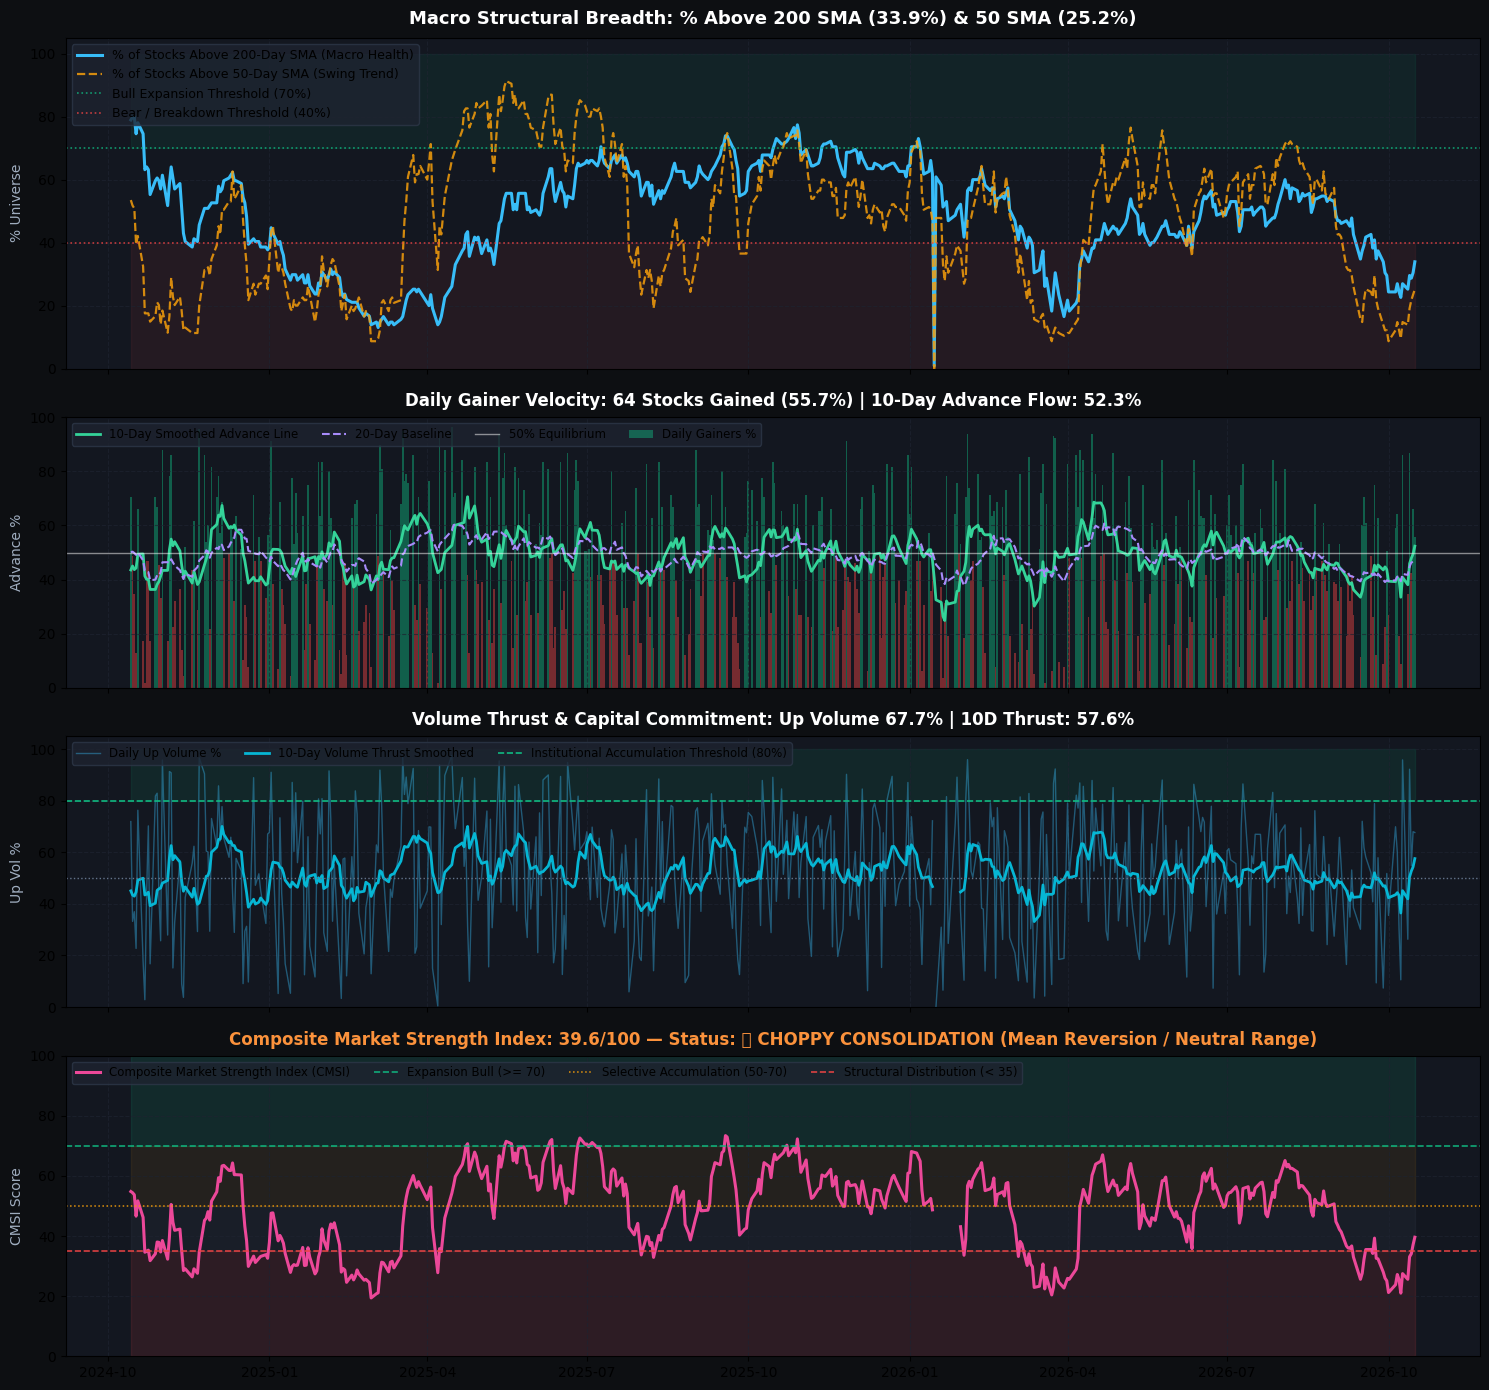

In [17]:
# Multi-Panel Institutional Market Breadth & Internal Strength Diagnostic Chart
def plot_market_breadth_diagnostic(lookback_days=500):
    """
    Plots a 4-panel institutional market strength dashboard:
    1. Macro Structural Breadth: % of Stocks Above 200 SMA & 50 SMA with Regime Bands
    2. Velocity Flow: Daily Gainer % vs. 10-Day & 20-Day Smoothed Advance Lines
    3. Volume Thrust: Daily Up Volume % vs. 80% Institutional Accumulation Threshold
    4. Composite Market Strength Index (CMSI) with Expansion/Distribution Regimes
    """
    plot_df = df_market_breadth.iloc[-lookback_days:].copy()
    dates = plot_df.index
    
    fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.8, 1.8, 2.0]})
    fig.patch.set_facecolor('#0d0f12')
    
    # ----------------------------------------------------
    # PANEL 1: Structural Breadth (% Above 200 & 50 SMA)
    # ----------------------------------------------------
    ax1 = axes[0]
    ax1.set_facecolor('#131720')
    ax1.plot(dates, plot_df['Pct_Above_200'], color='#38bdf8', lw=2.2, label='% of Stocks Above 200-Day SMA (Macro Health)')
    ax1.plot(dates, plot_df['Pct_Above_50'], color='#f59e0b', lw=1.6, alpha=0.85, ls='--', label='% of Stocks Above 50-Day SMA (Swing Trend)')
    
    # Threshold zones
    ax1.axhline(70.0, color='#10b981', ls=':', lw=1.2, alpha=0.8, label='Bull Expansion Threshold (70%)')
    ax1.axhline(40.0, color='#ef4444', ls=':', lw=1.2, alpha=0.8, label='Bear / Breakdown Threshold (40%)')
    ax1.fill_between(dates, 70, 100, color='#10b981', alpha=0.08)
    ax1.fill_between(dates, 0, 40, color='#ef4444', alpha=0.08)
    
    curr_200 = plot_df['Pct_Above_200'].iloc[-1]
    curr_50 = plot_df['Pct_Above_50'].iloc[-1]
    ax1.set_title(f"Macro Structural Breadth: % Above 200 SMA ({curr_200:.1f}%) & 50 SMA ({curr_50:.1f}%)", 
                  fontsize=13, fontweight='bold', color='#ffffff', pad=10)
    ax1.set_ylabel("% Universe", fontsize=10, color='#a0aec0')
    ax1.set_ylim(0, 105)
    ax1.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=9)
    ax1.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    # ----------------------------------------------------
    # PANEL 2: Daily Gainer Velocity & Flow Momentum
    # ----------------------------------------------------
    ax2 = axes[1]
    ax2.set_facecolor('#131720')
    
    # Color-coded daily gainer bars
    bar_colors = ['#10b981' if g >= 50.0 else '#ef4444' for g in plot_df['Pct_Daily_Gainers']]
    ax2.bar(dates, plot_df['Pct_Daily_Gainers'], color=bar_colors, width=1.0, alpha=0.45, label='Daily Gainers %')
    ax2.plot(dates, plot_df['Gainers_10SMA'], color='#34d399', lw=2.0, label='10-Day Smoothed Advance Line')
    ax2.plot(dates, plot_df['Gainers_20SMA'], color='#a78bfa', lw=1.5, ls='--', label='20-Day Baseline')
    ax2.axhline(50.0, color='#ffffff', ls='-', lw=1.0, alpha=0.5, label='50% Equilibrium')
    
    curr_gainers = plot_df['Pct_Daily_Gainers'].iloc[-1]
    curr_gain_count = int(plot_df['Daily_Gainers_Count'].iloc[-1])
    curr_10sma = plot_df['Gainers_10SMA'].iloc[-1]
    ax2.set_title(f"Daily Gainer Velocity: {curr_gain_count} Stocks Gained ({curr_gainers:.1f}%) | 10-Day Advance Flow: {curr_10sma:.1f}%", 
                  fontsize=12, fontweight='bold', color='#ffffff', pad=8)
    ax2.set_ylabel("Advance %", fontsize=10, color='#a0aec0')
    ax2.set_ylim(0, 100)
    ax2.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=8.5, ncol=4)
    ax2.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    # ----------------------------------------------------
    # PANEL 3: Volume Thrust (Up Volume % vs Down Volume %)
    # ----------------------------------------------------
    ax3 = axes[2]
    ax3.set_facecolor('#131720')
    ax3.plot(dates, plot_df['Pct_Up_Volume'], color='#38bdf8', lw=1.0, alpha=0.4, label='Daily Up Volume %')
    ax3.plot(dates, plot_df['Vol_Thrust_10SMA'], color='#06b6d4', lw=2.0, label='10-Day Volume Thrust Smoothed')
    ax3.axhline(80.0, color='#10b981', ls='--', lw=1.2, label='Institutional Accumulation Threshold (80%)')
    ax3.axhline(50.0, color='#64748b', ls=':', lw=1.0)
    ax3.fill_between(dates, 80, 100, color='#10b981', alpha=0.1)
    
    curr_upvol = plot_df['Pct_Up_Volume'].iloc[-1]
    curr_vt10 = plot_df['Vol_Thrust_10SMA'].iloc[-1]
    ax3.set_title(f"Volume Thrust & Capital Commitment: Up Volume {curr_upvol:.1f}% | 10D Thrust: {curr_vt10:.1f}%", 
                  fontsize=12, fontweight='bold', color='#ffffff', pad=8)
    ax3.set_ylabel("Up Vol %", fontsize=10, color='#a0aec0')
    ax3.set_ylim(0, 105)
    ax3.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=8.5, ncol=3)
    ax3.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    # ----------------------------------------------------
    # PANEL 4: Composite Market Strength Index (CMSI, 0-100)
    # ----------------------------------------------------
    ax4 = axes[3]
    ax4.set_facecolor('#131720')
    
    ax4.plot(dates, plot_df['CMSI'], color='#ec4899', lw=2.2, label='Composite Market Strength Index (CMSI)')
    
    # Fill regimes
    ax4.axhline(70.0, color='#10b981', ls='--', lw=1.2, alpha=0.9, label='Expansion Bull (>= 70)')
    ax4.axhline(50.0, color='#f59e0b', ls=':', lw=1.1, alpha=0.9, label='Selective Accumulation (50-70)')
    ax4.axhline(35.0, color='#ef4444', ls='--', lw=1.2, alpha=0.9, label='Structural Distribution (< 35)')
    
    ax4.fill_between(dates, 70, 100, color='#10b981', alpha=0.12)
    ax4.fill_between(dates, 50, 70, color='#f59e0b', alpha=0.08)
    ax4.fill_between(dates, 35, 50, color='#64748b', alpha=0.08)
    ax4.fill_between(dates, 0, 35, color='#ef4444', alpha=0.12)
    
    curr_cmsi = plot_df['CMSI'].iloc[-1]
    if curr_cmsi >= 70:
        regime_txt = "🟢 STRONG BULL EXPANSION (Aggressive Longs / Breakouts Favored)"
        regime_col = '#10b981'
    elif curr_cmsi >= 50:
        regime_txt = "🟡 SELECTIVE ACCUMULATION (Stock-Picking / Demand Dip Buying)"
        regime_col = '#f59e0b'
    elif curr_cmsi >= 35:
        regime_txt = "🟠 CHOPPY CONSOLIDATION (Mean Reversion / Neutral Range)"
        regime_col = '#fb923c'
    else:
        regime_txt = "🔴 STRUCTURAL DISTRIBUTION (Defensive / Tight Stops / Cash)"
        regime_col = '#ef4444'
        
    ax4.set_title(f"Composite Market Strength Index: {curr_cmsi:.1f}/100 — Status: {regime_txt}", 
                  fontsize=12, fontweight='bold', color=regime_col, pad=8)
    ax4.set_ylabel("CMSI Score", fontsize=10, color='#a0aec0')
    ax4.set_ylim(0, 100)
    ax4.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=8.5, ncol=4)
    ax4.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

# Render diagnostic chart over trailing 500 sessions (~2 years)
plot_market_breadth_diagnostic(lookback_days=500)


In [18]:
# Executive Market Strength & Breadth Leadership Diagnostic Table
latest = df_market_breadth.iloc[-1]
prev_1w = df_market_breadth.iloc[-6]
prev_1m = df_market_breadth.iloc[-22]

summary_records = [
    {
        'Metric': 'Stocks Above 200-Day SMA',
        'Current': f"{int(latest['Above_200_Count'])} / {int(latest['Total_Stocks'])} ({latest['Pct_Above_200']:.1f}%)",
        '1-Week Ago': f"{prev_1w['Pct_Above_200']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Above_200']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Above_200'] - prev_1m['Pct_Above_200']:+.1f}%",
        'Significance': 'Institutional macro trendline; expansion confirms broad sector health'
    },
    {
        'Metric': 'Stocks Above 50-Day SMA',
        'Current': f"{latest['Pct_Above_50']:.1f}%",
        '1-Week Ago': f"{prev_1w['Pct_Above_50']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Above_50']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Above_50'] - prev_1m['Pct_Above_50']:+.1f}%",
        'Significance': 'Intermediate swing breadth; crosses above 200 SMA signal expansion waves'
    },
    {
        'Metric': 'Stocks Above 20-Day EMA',
        'Current': f"{latest['Pct_Above_20']:.1f}%",
        '1-Week Ago': f"{prev_1w['Pct_Above_20']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Above_20']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Above_20'] - prev_1m['Pct_Above_20']:+.1f}%",
        'Significance': 'Fast short-term momentum; leads 50 & 200 SMA inflections by 10-15 days'
    },
    {
        'Metric': 'Daily Gainers Velocity',
        'Current': f"{int(latest['Daily_Gainers_Count'])} Gainers ({latest['Pct_Daily_Gainers']:.1f}%)",
        '1-Week Ago': f"{prev_1w['Pct_Daily_Gainers']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Daily_Gainers']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Daily_Gainers'] - prev_1m['Pct_Daily_Gainers']:+.1f}%",
        'Significance': 'Daily participation breadth; > 65% signals broad-based buying thrust'
    },
    {
        'Metric': '10-Day Smoothed Advance Flow',
        'Current': f"{latest['Gainers_10SMA']:.1f}%",
        '1-Week Ago': f"{prev_1w['Gainers_10SMA']:.1f}%",
        '1-Month Ago': f"{prev_1m['Gainers_10SMA']:.1f}%",
        '1-Month Shift': f"{latest['Gainers_10SMA'] - prev_1m['Gainers_10SMA']:+.1f}%",
        'Significance': 'Filters single-day whipsaws; sustained > 50% confirms buyers in control'
    },
    {
        'Metric': 'Volume Thrust (Up Volume %)',
        'Current': f"{latest['Pct_Up_Volume']:.1f}%",
        '1-Week Ago': f"{prev_1w['Pct_Up_Volume']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Up_Volume']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Up_Volume'] - prev_1m['Pct_Up_Volume']:+.1f}%",
        'Significance': 'Turnover commitment; > 80% marks institutional accumulation days'
    },
    {
        'Metric': 'McClellan Breadth Oscillator',
        'Current': f"{latest['McClellan_Osc']:+.2f}",
        '1-Week Ago': f"{prev_1w['McClellan_Osc']:+.2f}",
        '1-Month Ago': f"{prev_1m['McClellan_Osc']:+.2f}",
        '1-Month Shift': f"{latest['McClellan_Osc'] - prev_1m['McClellan_Osc']:+.2f}",
        'Significance': 'Breadth momentum; positive cross indicates acceleration of net buying'
    },
    {
        'Metric': 'Composite Market Strength (CMSI)',
        'Current': f"{latest['CMSI']:.1f} / 100",
        '1-Week Ago': f"{prev_1w['CMSI']:.1f}",
        '1-Month Ago': f"{prev_1m['CMSI']:.1f}",
        '1-Month Shift': f"{latest['CMSI'] - prev_1m['CMSI']:+.1f}",
        'Significance': 'Multi-factor composite gauge synthesized across all 5 breadth dimensions'
    }
]

df_summary_report = pd.DataFrame(summary_records)
print("=== TRADEKRIYA INSTITUTIONAL MARKET STRENGTH REPORT ===")
print(f"Data Cut: {latest.name.strftime('%A, %d %B %Y')}")
print(f"Market Regime: {'BULL EXPANSION' if latest['CMSI']>=70 else ('SELECTIVE ACCUMULATION' if latest['CMSI']>=50 else ('CHOPPY NEUTRAL' if latest['CMSI']>=35 else 'DISTRIBUTION RISK'))}\n")
print(df_summary_report[['Metric', 'Current', '1-Month Shift', 'Significance']].to_string(index=False))


=== TRADEKRIYA INSTITUTIONAL MARKET STRENGTH REPORT ===
Data Cut: Friday, 16 October 2026
Market Regime: CHOPPY NEUTRAL

                          Metric            Current 1-Month Shift                                                             Significance
        Stocks Above 200-Day SMA   39 / 115 (33.9%)         -3.5%    Institutional macro trendline; expansion confirms broad sector health
         Stocks Above 50-Day SMA              25.2%        +10.4% Intermediate swing breadth; crosses above 200 SMA signal expansion waves
         Stocks Above 20-Day EMA              41.7%        +30.4%   Fast short-term momentum; leads 50 & 200 SMA inflections by 10-15 days
          Daily Gainers Velocity 64 Gainers (55.7%)         -4.3%     Daily participation breadth; > 65% signals broad-based buying thrust
    10-Day Smoothed Advance Flow              52.3%        +16.7%  Filters single-day whipsaws; sustained > 50% confirms buyers in control
     Volume Thrust (Up Volume %)             